# 001 — Profilage initial du jeu de données `Cybersecurity-Dataset-v1`

### TDSP — Phase 2 : Data Acquisition and Understanding
**Projet :** Cybersecurity-NLP-GraphRAG-QA (S2 · Analyse de texte et question-réponse)

- **Objectif du notebook :** établir une compréhension fiable et reproductible du jeu de données, avant toute modélisation (Phase 3).
- **Nature de l'analyse :** lecture strictement en lecture seule ; aucune modification des données sources.
- **Références :**
  1. Jeu de données Hugging Face : [`AlicanKiraz0/Cybersecurity-Dataset-v1`](https://huggingface.co/datasets/AlicanKiraz0/Cybersecurity-Dataset-v1) (fiche consultée le 29/10/2026).
  2. Rapport de cadrage TDSP : `docs/tdsp/Rapport_Business_Understanding.pdf` (§ Data Understanding et préparation).
  3. Compte rendu des phases 1–2 : `docs/tdsp/PHASES_1_2.md`.

> **Remarque importante.** Tous les chiffres affichés sont **calculés lors de l'exécution** ; aucun résultat n'est codé en dur. Le notebook doit être exécuté de haut en bas, dans un environnement propre, pour être valide.

## Sommaire du notebook

Chaque chiffre est **recalculé à l'exécution** ; aucun résultat codé en dur. Les statuts *exploratoire* / *candidat* / *confirmé* sont indiqués au fil des sections.

| § | Titre | Ce qui est mesuré / produit | Cellules |
|---|---|---|---|
| 1 | Objectif et périmètre | cadrage TDSP Phase 2 ; inclus / exclus explicitement | `cell-01-s1` |
| 2 | Configuration et acquisition | environnement (versions), graine 42, empreinte SHA-256 du parquet, chargement, schéma vérifié | `cell-02` → `cell-06` |
| 3 | Qualité structurelle | manquants / vides / blancs par colonne ; doublons de lignes exacts ; anomalies de format (`think`, `hedge`, U+FFFD, CVE/IPv4 bruts) | `cell-07` → `cell-10` |
| 4 | Statistiques descriptives | longueurs (caractères, mots), tokens GPT-2 par champ, corrélations | `cell-11` → `cell-13` |
| 5 | Visualisations | barres des cellules défectueuses, histogrammes, boîtes, corrélations | `cell-14` → `cell-18` |
| 6 | Inspection manuelle | échantillons masqués (redaction) pour revue humaine | `cell-19` → `cell-20` |
| 7 | Déduplication normalisée + similarité sémantique | doublons normalisés (strict / large) des questions et des paires Q/R ; embeddings `all-MiniLM-L6-v2` (GPU si disponible) ; distribution kNN ; groupes redondants (cosinus ≥ 0,85) | `cell-27` → `cell-30` |
| 8 | Couverture thématique candidate | classes par lexique (multi-classes / sans classe) ; TF-IDF + k-means (k choisi par silhouette) ; croisement lexique × clusters | `cell-31` → `cell-33` |
| 9 | Revue de l'assistant | refus (fenêtre 600 car.) × risque ; échantillon d'adjudication ; complétude (troncatures, blocs de code, gabarits) | `cell-34` → `cell-36` |
| 10 | Entités candidates renforcées | CVE validées (année plausible, séquence ≥ 100) ; IPv4 publiques / privées (RFC 1918) ; échantillons contextuels | `cell-37` → `cell-38` |
| 11 | Dossier des lignes incomplètes | identifiants recalculés, contexte ± 1 ligne, matrice de décision (annoter / exclure / compléter) | `cell-39` → `cell-40` |
| 12 | Premiers constats de qualité | consolidation des contrôles structurels des sections 3 à 6 | `cell-21` → `cell-22` |
| 13 | Limites mises à jour et prochaines étapes | portée exacte de la v2 ; priorités ; hypothèses de travail à ne pas considérer comme des résultats | `cell-23` |
| 14 | Synthèse exécutive et évaluation finale | statut de préparation ; empreinte `final_stamped` (métriques v2 incluses) | `cell-24` → `cell-25` |

Les sections 7 à 11 (v2) répondent aux six limites relevées dans la v1 ; les sections 12 à 14 consolident les constats, qualifient les limites restantes et synthétisent le profilage.


## Index du code — cellule par cellule

Référence rapide pour la revue et l'exécution : chaque cellule de code, son rôle, et les variables qu'il définit (consumées par les sections suivantes). Les fonctions d'affichage (`afficher_records`, `masque_sensible`) vivent en S6 et sont réutilisées en S9/S11.

| Cellule | Rôle | Définit / exporte |
|---|---|---|
| `cell-03-config` | imports, versions affichées, reproductibilité | `SEED = 42` ; modules (pandas, numpy, matplotlib, re, unicodedata, datetime, hashlib) |
| `cell-04-chemins` | chemins du projet + traçabilité de la source | `PROVENANCE` (option de lecture, chemin local, schéma attendu) |
| `cell-05-chargement` | lecture du Parquet local, empreinte | `sha256_of_file()` ; `df_raw` (lecture seule) ; `PROVENANCE["sha256"]` |
| `cell-06-schema` | vérification des colonnes/dtypes + aperçu tronqué | schéma observé vs attendu |
| `cell-08-manquants` | santé structurelle par colonne | `resume_structurel()` → `structure` (manquants/vides/blancs/non_str/uniques) ; `nb_lignes` |
| `cell-09-doublons` | doublons exacts + lignes mal formées | `doublons_strict` ; `masque_defectueux` ; `lignes_defectueuses` ; index des lignes |
| `cell-10-anomalies` | anomalies de format sans transformation | `RE_CVE`, `RE_IP`, `RE_UFFFD`, `est_ipv4` ; dict `anomalies` (U+FFFD, `think`, `<hedge>`, CVE/IPv4 bruts) |
| `cell-12-stats` | statistiques descriptives par champ | `longueurs_car` (caractères, mots, percentiles) |
| `cell-13-tokens` | encombrement en tokens (tokenizer réel nommé) | table tokens `gpt2` par champ |
| `cell-15-viz-missing` | fig. 1 — barres % défectueux par colonne | figure matplotlib (manquants/vides/blancs) |
| `cell-16-viz-hist` | fig. 2 — histogrammes de longueur (échelle log) | figures par champ |
| `cell-17-viz-box` | fig. 3 — boîtes user vs assistant | figure (médianes, queues) |
| `cell-18-viz-corr` | fig. 4 — corrélations des longueurs | nuage user↔assistant ; `r_pearson` |
| `cell-20-echantillon` | inspection manuelle reproductible et masquée | `afficher_records()` ; `masque_sensible()` ; échantillons (typiques, courts, longs, suspects) |
| `cell-22-constats` | table des premiers constats consolidés | DataFrame `constats` (effectifs, %, preuves, actions) |
| `cell-25-synthese` | synthèse exécutive v2 + empreinte | `pct_str()` ; `metriques_v2` ; `statut_prepare` + justification ; lignes A–F ; `final_stamped` |
| `cell-28-dedup` (S7.1) | déduplication normalisée, deux niveaux, copies | `normaliser_strict()`, `normaliser_loose()` ; `u/r_norm_strict`, `u/r_norm_loose` ; `n_dedup_user/paire_*` ; table `q_dedup` |
| `cell-29-embeddings` (S7.2) | embeddings + distribution kNN (GPU si dispo) | `modele_st` (`all-MiniLM-L6-v2`) ; `emb_user`, `emb_ass` (l2) ; `bilan_knn()` ; `n_pairs_sem_u/a` ; histogramme |
| `cell-30-clusters` (S7.3) | groupes de redondance (cosinus ≥ 0,85) | `labels_user` ; `n_groupes_redundance` ; `n_lignes_redundantes` ; aperçu des groupes |
| `cell-32-lexique` (S8.1) | classes candidates par lexique | `LEXIQUE_CLASSES` ; `SANS_CLASSE` ; `classe_par_ligne` ; `q_classe` ; `n_multi_classe` ; `n_sans_classe` |
| `cell-33-kmeans` (S8.2) | thèmes émergents TF-IDF + k-means | matrice TF-IDF ; balayage k=6..12 (silhouette) ; `k_final` ; `kmeans_final` ; top termes ; croisement lexique × cluster |
| `cell-35-refus` (S9.1) | motifs de refus × risque + adjudication | `MOTIFS_REFUS`, `MOTIFS_RISQUE`, `contient_motifs()` ; `refus_debut` ; `risque_ligne` ; `crosstab_refus` ; `n_refus`, `n_risque`, `taux_refus_*` ; échantillon |
| `cell-36-boiler` (S9.2) | complétude structurelle + gabarits | `fin_reponse_sans_signe()` ; `n_reponses_tronq`, `n_blocs_code`, `n_titres_md`, `n_urls` ; `boilerplates` ; `n_lignes_gabarit` ; `n_tronq` |
| `cell-38-entites` (S10.1) | candidats renforcés CVE/IPv4 | `RE_CVE_FORT`, `RE_IP_FORT` ; `octets_ip_ok()`, `ip_privee()`, `contexte_autour()` ; ensembles + `nb_cve_distinctes`, `nb_ip_pub/priv`, `cve_rejetes` ; `q_entites` ; échantillons contextuels |
| `cell-40-dossier` (S11.1) | dossier des lignes incomplètes | `ids_incomplets` ; `df_incomplets` ; contexte ± 1 ligne masqué ; `matrice_decision` (annoter / exclure / compléter) |

Dépendance d'exécution : S7→S9 réutilisent les copies normalisées de S7.1 ; la synthèse (S14) agrège toutes les métriques ; rien ne modifie la source.

# 001 — Profilage initial du jeu de données `Cybersecurity-Dataset-v1`

### TDSP — Phase 2 : Data Acquisition and Understanding
**Projet :** Cybersecurity-NLP-GraphRAG-QA (S2 · Analyse de texte et question-réponse) — **édition v2**

- **Objectif :** comprendre le corpus avant toute modélisation (Phase 3), et traiter les six limites relevées par la v1.
- **v2 :** les sections 7 à 11 prolongent le profilage initial (déduplication normalisée, similarité sémantique, classes candidates, motifs de refus, candidats renforcés, dossier des lignes incomplètes).
- **Lecture seule :** la source n'est jamais modifiée ; chaque mesure s'effectue sur des **copies normalisées** créées puis calculées à l'exécution.
- **Références :** fiche dataset `[1]` (AlicanKiraz0/Cybersecurity-Dataset-v1) ; rapport TDSP `docs/tdsp/Rapport_Business_Understanding.pdf` `[2]` ; phases 1–2 `docs/tdsp/PHASES_1_2.md` `[3]`.

> **Tous les chiffres affichés sont recalculés lors de l'exécution.** Exécuter de haut en bas, dans un environnement propre.

## Section 1 — Objectif et périmètre

### 1.1 Rôle dans la Phase 2 du TDSP

La Phase 2, « Data Acquisition and Understanding », vise à acquérir les données, vérifier leur intégrité et produire une compréhension documentée et reproductible de leur contenu. Ce notebook réalise le **profilage du corpus** : structure, statistiques descriptives, anomalies, puis analyses exploratoires secondaires (sections 7 à 11).

### 1.2 Périmètre inclus / exclu

| Inclus (sections 2 à 11) | Exclu explicitement |
|---|---|
| Structure, types, valeurs manquantes, doublons exacts | Déduplication sémantique **certifiée par revue humaine** |
| Statistiques de longueur + visualisations | Évaluation de la **véracité** des réponses |
| Proximités sémantiques par embeddings (exploratoire) | Classification supervisée (Phase 3) |
| Classes par lexique + thèmes k-means (candidates) | Étiquettes de classe définitives |
| Motifs de refus × risque + échantillons d'adjudication | Certificats de conformité éthique |
| CVE/IPv4 candidates renforcées ; dossier lignes incomplètes | Toute modification du dataset |

### 1.3 Petits rappels techniques (approche Feynman)

- Un **embedding** transforme un texte en un vecteur numérique ; deux textes proches en vecteurs parlent de la même chose — utile pour repérer la redondance au-delà des doublons littéraux.
- Une **silhouette** mesure la cohérence d'un clustering : haute = clusters compacts et séparés.
- Un **lexique** est une liste de mots-clés de travail ; sa couverture dépend de sa qualité et restera sous-approximatif par nature.

### 1.4 Ce que ce notebook inclut — et n'inclut pas

**Inclus :** validation structurelle, valeurs manquantes, doublons puis redondances, statistiques de longueur, visualisations, inspection d'échantillons, similarité sémantique exploratoire, classes candidates, motifs de refus, candidats CVE/IPv4 renforcés, dossier des lignes incomplètes.

**Exclus :** annotation définitive, évaluation factuelle, entraînement ou évaluation de modèle, transformation du dataset. Ces activités appartiennent aux phases suivantes (voir `[3]`).

## Section 2 — Environnement et chargement du jeu de données

Dans cette section, nous :
1. importons les bibliothèques strictement nécessaires ;
2. fixons l'aléatoire pour des échantillons reproductibles ;
3. téléchargeons le fichier Parquet publié sur Hugging Face et calculons son empreinte SHA-256 (traçabilité) ;
4. vérifions que le schéma observé correspond aux attentes.

Le chargement **échoue clairement** si les données sont introuvables : aucune donnée de substitution n'est jamais utilisée.

In [1]:
# Imports strictement nécessaires — Pandas/NumPy/Matplotlib conviennent à ce profilage.

import hashlib
import json
import re
import time
import unicodedata
import warnings
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Reproductibilité : une seule source d'aléa, une graine explicite.
SEED = 42
np.random.seed(SEED)

# Affichage : tronquer proprement pour l'inspection, ne pas masquer d'avertissement.
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 120)

# Un seul style pour toutes les figures du notebook.
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")
print(f"Python version exécutée : {Path('/usr/bin/env').exists()} ")

pandas 3.1.0 | numpy 2.5.4 | matplotlib 3.11.2
Python version exécutée : True 


In [3]:
# Chemins et configuration — informations de provenance (traçabilité du corpus).

def find_repo_root(start: Path | None = None) -> Path:
    """Remonte l'arborescence jusqu'à la racine du dépôt (celle qui contient pyproject.toml)."""
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Racine du dépôt introuvable (pyproject.toml absent).")


ROOT = find_repo_root()

# Identité de la source : dépôt Hugging Face + fichier Parquet du split train.
DATASET_ID = "AlicanKiraz0/Cybersecurity-Dataset-v1"
PARQUET_FILE = "cybersecurity-dataset-train-data.parquet"

PROVENANCE = {
    "dataset_id": DATASET_ID,
    "fichier": PARQUET_FILE,
    "format": "Parquet (Hugging Face Hub)",
    "date_execution": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED,
    "racine_projet": str(ROOT),
    "notebook": "ml/notebooks/001-EDA.ipynb",
}
print(json.dumps(PROVENANCE, indent=2, ensure_ascii=False))

{
  "dataset_id": "AlicanKiraz0/Cybersecurity-Dataset-v1",
  "fichier": "cybersecurity-dataset-train-data.parquet",
  "format": "Parquet (Hugging Face Hub)",
  "date_execution": "2026-10-30T09:37:27+00:00",
  "seed": 42,
  "racine_projet": "/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA",
  "notebook": "ml/notebooks/001-EDA.ipynb"
}


In [4]:
# Chargement des données.
# Deux approches équivalentes permettent de lire ce Parquet :
#   (a) df = pd.read_parquet("hf://datasets/AlicanKiraz0/Cybersecurity-Dataset-v1/cybersecurity-dataset-train-data.parquet")
#   (b) téléchargement explicite via huggingface_hub, puis lecture du fichier local.
# Nous retenons (b) : elle fournit un chemin local vérifiable + une empreinte SHA-256 (traçabilité).

from huggingface_hub import hf_hub_download
from huggingface_hub.utils import HfHubHTTPError, EntryNotFoundError


def sha256_of_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Calcule l'empreinte SHA-256 d'un fichier, par blocs (loop mémoire constante)."""
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


# Authentification : jeton issu de `hf auth login` (cache local) ou variable HF_TOKEN.
try:
    local_file = hf_hub_download(
        repo_id=DATASET_ID, repo_type="dataset", filename=PARQUET_FILE
    )
except (HfHubHTTPError, EntryNotFoundError, OSError) as exc:
    raise RuntimeError(
        f"Échec du téléchargement du dataset '{DATASET_ID}' : {exc}\n"
        f"Vérifiez : (1) la connexion Internet, (2) l'authentification via `hf auth login`,"
        f" (3) l'existence du fichier '{PARQUET_FILE}' sur le dépôt."
        " Aucune donnée de substitution n'est utilisée — le notebook s'arrête ici."
    ) from exc

local_path = Path(local_file)
PROVENANCE["chemin_local"] = str(local_path)
PROVENANCE["taille_octets"] = local_path.stat().st_size
PROVENANCE["sha256"] = sha256_of_file(local_path)

df_raw = pd.read_parquet(local_path)  # lecture seule ; jamais réécrite par ce notebook

# Validation du chargement : instance attendue, non vide, avec des colonnes.
if not isinstance(df_raw, pd.DataFrame):
    raise TypeError(f"Objet inattendu après lecture Parquet : {type(df_raw)!r}")
if df_raw.empty:
    raise ValueError("Le Parquet chargé est vide (0 ligne) — arrêt pour inspection manuelle.")
if df_raw.columns.empty:
    raise ValueError("Le Parquet chargé n'a aucune colonne — arrêt pour inspection manuelle.")

print(f"Chargement OK — fichier local : {local_path}")
print(f" Dimensions : {df_raw.shape[0]:,} lignes × {df_raw.shape[1]} colonnes")
print(f" Empreinte SHA-256 du fichier : {PROVENANCE['sha256']}")
print(f" Taille du fichier : {PROVENANCE['taille_octets'] / 1e6:.2f} Mo")

/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Chargement OK — fichier local : /home/magreyuptown/.cache/huggingface/hub/datasets--AlicanKiraz0--Cybersecurity-Dataset-v1/snapshots/410b35d53b8b1d49b9b781760a32147b2946698c/cybersecurity-dataset-train-data.parquet
 Dimensions : 2,411 lignes × 3 colonnes
 Empreinte SHA-256 du fichier : 6b1092bce6d219a50cd5ff3487a068cb368e2fd08a0f469c7c7314935d6473aa
 Taille du fichier : 3.89 Mo


In [5]:
# Schéma observé : colonnes, types, première ligne tronquée (vérification visuelle initiale).

EXPECTED_COLUMNS = {"system", "user", "assistant"}

print("Colonnes observées :", list(df_raw.columns))
print("Types pandas :")
print(df_raw.dtypes.to_string())

schema_matches = EXPECTED_COLUMNS.issubset(set(df_raw.columns))
PROVENANCE["schema_attendu_present"] = bool(schema_matches)
print(f"\nSchéma attendu ({{'system','user','assistant'}}) présent : {schema_matches}")
if not schema_matches:
    raise ValueError("Colonnes attendues absentes — le schéma ne correspond pas à nos hypothèses.")


def apercu_tronque(texte: object, largeur: int = 160) -> str:
    """Rend un texte imprimable en une ligne, tronqué à `largeur` caractères."""
    if not isinstance(texte, str):
        return f"« {type(texte).__name__} »"
    compact = " ".join(texte.split())
    return compact if len(compact) <= largeur else compact[:largeur] + "…"


aperçu = df_raw.head(2).copy()
for colonne in df_raw.columns:
    aperçu[colonne] = aperçu[colonne].map(apercu_tronque)
display(aperçu)
print("Lecture visuelle rapide : au moins une ligne ressemble au format instruction–réponse attendu.")
print("La vérification approfondie du contenu suit en Section 6.")

Colonnes observées : ['system', 'user', 'assistant']
Types pandas :
system       str
user         str
assistant    str

Schéma attendu ({'system','user','assistant'}) présent : True


,system,user,assistant
0,"You are a highly specialized AI assistant for advanced cyber-defense whose mission is to deliver accurate, in-depth,...",Explain the fundamental data flow of a Reflected XSS attack. Describe the journey of the malicious payload from the ...,Reflected XSS attacks occur when an attacker sends a request containing a malicious script to a vulnerable applicati...
1,"You are a highly specialized AI assistant for advanced cyber-defense whose mission is to deliver accurate, in-depth,...",How does a Reflected XSS vulnerability in an API endpoint that returns a Content-Type of application/json differ fro...,The difference between reflected cross-site scripting (XSS) vulnerabilities in a web page versus those in an API end...


Lecture visuelle rapide : au moins une ligne ressemble au format instruction–réponse attendu.
La vérification approfondie du contenu suit en Section 6.


## Section 3 — Validation structurelle

Nous vérifions maintenant la **santé structurelle** du tableau :

- valeurs manquantes (`NaN`, `None`), chaînes vides et chaînes d'espaces — trois notions distinctes ;
- types inattendus (tout ce qui n'est pas `str` dans un champ censé l'être) ;
- lignes mal formées (au moins un champ défectueux) ;
- doublons exacts de lignes ;
- doublons intra-colonne, en distinguant la **répétition légitime** (ex. : la même consigne `system` réutilisée à l'identique) d'une répétition suspecte (ex. : la même question posée plusieurs fois).

Chaque métrique est rapportée en **valeur absolue et en pourcentage**.

In [6]:
# Valeurs manquantes vs chaînes vides vs chaînes d'espaces — trois diagnostics distincts.

def resume_structurel(cadre: pd.DataFrame) -> pd.DataFrame:
    """Tableau de santé structurale par colonne : absences, vides, blancs, types, unicités.

    Conventions :
    - `manquants` : NaN/None détectés par isna() ;
    - `vides` : chaînes de longueur nulle ("") ;
    - `blancs` : chaînes composées d'espaces uniquement (après strip, non vides au départ) ;
    - `non_str` : objets dont le type n'est ni str ni une valeur manquante reconnue.
    """
    lignes = []
    n = len(cadre)
    for colonne in cadre.columns:
        série = cadre[colonne]
        manquants = int(série.isna().sum())
        est_chaînes = série.map(lambda v: isinstance(v, str) and not pd.isna(v))
        chaînes = série[est_chaînes]
        vides = int((chaînes == "").sum())
        blancs = int((chaînes.str.strip() == "").sum() - (chaînes == "").sum())
        non_str = int((série.notna() & ~est_chaînes).sum())
        uniques = int(séria_nunique := série.nunique(dropna=True))
        lignes.append({
            "colonne": colonne,
            "dtype": str(série.dtype),
            "manquants": manquants,
            "pct_manquants": 100.0 * manquants / n,
            "vides": vides,
            "pct_vides": 100.0 * vides / n,
            "blancs": blancs,
            "pct_blancs": 100.0 * blancs / n,
            "non_str": non_str,
            "pct_non_str": 100.0 * non_str / n,
            "valeurs_uniques": uniques,
        })
    return pd.DataFrame(lignes).set_index("colonne")


structure = resume_structurel(df_raw)
display(structure.round(3))

nb_lignes = len(df_raw)
n_display = 3
print(f"\nN = {nb_lignes:,} lignes. Les pourcentages s'entendent sur ces {nb_lignes:,} lignes.")

,dtype,manquants,pct_manquants,vides,pct_vides,blancs,pct_blancs,non_str,pct_non_str,valeurs_uniques
colonne,,,,,,,,,,
system,str,1,0.041,0,0.0,0,0.0,0,0.0,1
user,str,1,0.041,0,0.0,0,0.0,0,0.0,2395
assistant,str,2,0.083,0,0.0,0,0.0,0,0.0,2409



N = 2,411 lignes. Les pourcentages s'entendent sur ces 2,411 lignes.


In [7]:
# Doublons exacts et lignes mal formées.

# 1) Doublons de lignes complètes (toutes les colonnes identiques).
doublons_lignes = int(df_raw.duplicated(keep=False).sum())
doublons_strict = int(df_raw.duplicated().sum())  # copies en plus de la première occurrence

# 2) Doublons par colonne — attention au sens : une consigne `system` répétée est attendue.
doublons_par_colonne = {
    colonne: int(df_raw[colonne].duplicated().sum()) for colonne in df_raw.columns
}

# 3) Lignes mal formées : au moins un champ manquant / vide / blanc / non-chaîne.
masque_defectueux = pd.Series(False, index=df_raw.index)
motifs_defectueux = {}
for colonne in df_raw.columns:
    série = df_raw[colonne]
    est_manquant = série.isna()
    est_non_str = série.notna() & ~série.map(lambda v: isinstance(v, str))
    chaînes = série[série.map(lambda v: isinstance(v, str))]
    est_vide = série.map(lambda v: isinstance(v, str) and v.strip() == "")
    for nom, masque in (("manquant", est_manquant), ("non_str", est_non_str), ("vide", est_vide)):
        ids = masque[masque].index
        if len(ids):
            motifs_defectueux.setdefault(nom, []).extend(ids)
    masque_defectueux |= est_manquant | est_non_str | est_vide

lignes_defectueuses = int(masque_defectueux.sum())

synth = pd.DataFrame({
    "doublons_lignes_exactes": [doublons_strict],
    "lignes_affectees_doublons": [doublons_lignes],
    "lignes_defectueuses": [lignes_defectueuses],
})
synth.insert(1, "pct_doublons", 100.0 * doublons_strict / nb_lignes)
synth.insert(3, "pct_defectueuses", 100.0 * lignes_defectueuses / nb_lignes)
display(synth.round(3))

print("Doublons par colonne (occurrences en plus de la 1re visite) :")
print({k: v for k, v in doublons_par_colonne.items()})

if lignes_defectueuses:
    print(f"\nIndex des lignes mal formées (max 15 affichés) : {sorted(set(motifs_defectueux.get('manquant', []) + motifs_defectueux.get('vide', []) + motifs_defectueux.get('non_str', [])))[:15]}")
    échantillon_defectueux = df_raw.loc[
        sorted(set(motifs_defectueux.get('manquant', []) + motifs_defectueux.get('vide', []) + motifs_defectueux.get('non_str', [])))[:3]
    ].copy()
    for colonne in df_raw.columns:
        échantillon_defectueux[colonne] = échantillon_defectueux[colonne].map(lambda v: v if isinstance(v, str) else repr(v))
        échantillon_defectueux[colonne] = échantillon_defectueux[colonne].map(lambda v: len(v) > 120 and v[:120] + "…" or v)
else:
    échantillon_defectueux = df_raw.head(0)
print(display(échantillon_defectueux) if lignes_defectueuses else "\nAucune ligne mal formée détectée par les filtres ci-dessus.")

,doublons_lignes_exactes,pct_doublons,lignes_affectees_doublons,pct_defectueuses,lignes_defectueuses
0,0,0.0,0,0.083,2


Doublons par colonne (occurrences en plus de la 1re visite) :
{'system': 2409, 'user': 15, 'assistant': 1}

Index des lignes mal formées (max 15 affichés) : [253, 850]


,system,user,assistant
253,nan,nan,nan
850,"You are a highly specialized AI assistant for advanced cyber-defense whose mission is to deliver accurate, in-depth,...",Explain the implementation details of fileless malware that abuses COM hijacking and phantom DLL loading to achieve ...,nan


None


In [8]:
# Anomalies de format détectables sans transformation destructrice.
# Idées clés :
#   - caractères U+FFFD : symptôme d'une erreur d'encodage antérieure ;
#   - espaces de début/fin : bruit bénin mais révélateur d'un futur pipeline de préparation à cadrer ;
#   - blocs  hedge…/shadow…/think : artefacts de génération à neutraliser plus tard ;
#   - entités techniques (CVE, IP) : candidates pour la Phase 3 — jamais des annotations validées.

RE_UFFFD = re.compile(r"\ufffd")
RE_BLOCS = re.compile(r"<think>|</think>|think\b", re.IGNORECASE)
RE_SHA = re.compile(r"</?think>")
RE_HEDGE = re.compile(r"</?hedge>")
RE_SHA2 = re.compile(r"</?think>")
RE_CVE = re.compile(r"CVE-\d{4}-\d{4,7}")
RE_IP = re.compile(r"(?:\d{1,3}\.){3}\d{1,3}")


def est_ipv4(candidate: str) -> bool:
    """Vérifie 4 octets ≤ 255 (écarte faussement '1.2.3.4' des IP)."""
    parts = candidate.split(".")
    return len(parts) == 4 and all(part.isdigit() and int(part) <= 255 for part in parts)


stats_anomalies = []
longueurs_car = {}
for colonne in df_raw.columns:
    texte = df_raw[colonne]
    longueurs_car[colonne] = texte.map(lambda v: len(v) if isinstance(v, str) else np.nan)
    chaînes = texte[texte.map(lambda v: isinstance(v, str))]
    stats_anomalies.append({
        "colonne": colonne,
        "bord_droit_ou_gauche": int(chaînes.map(lambda s: s != s.strip()).sum()),
        "contient_U+FFFD": int(chaînes.str.contains(RE_UFFFD).sum()),
        "contient_<think>|think": int(chaînes.str.contains("think", case=False).sum()),
        "contient_<hedge>": int(chaînes.str.contains("hedge", case=False).sum()),
        "mentions_CVE": int(chaînes.str.findall(RE_CVE).map(len).gt(0).sum()),
        "mentions_IPv4": int(chaînes.str.findall(RE_IP).map(lambda l: [p for p in l if est_ipv4(p)]).map(bool).sum()),
    })

anomalies = pd.DataFrame(stats_anomalies).set_index("colonne")
display(anomalies)
print("\nPhrase d'interprétation :")
print("- 'bord_gauche_ou_droite' > 0 : textes non nettoyés -> intervention en Section 4/Phase 3 prévue")
print("- 'contient_think|think' > 0 : bloc de raisonnement du modèle à retirer de la copie nettoyée (jamais de la source)")
print("- CVE / IPv4 : présence d'entités techniques réutilisables pour le graphe de connaissances (Phase 4)")


,bord_droit_ou_gauche,contient_U+FFFD,contient_<think>|think,contient_<hedge>,mentions_CVE,mentions_IPv4
colonne,,,,,,
system,0,0,0,0,0,0
user,0,0,0,0,1,2
assistant,0,0,447,0,69,31



Phrase d'interprétation :
- 'bord_gauche_ou_droite' > 0 : textes non nettoyés -> intervention en Section 4/Phase 3 prévue
- 'contient_think|think' > 0 : bloc de raisonnement du modèle à retirer de la copie nettoyée (jamais de la source)
- CVE / IPv4 : présence d'entités techniques réutilisables pour le graphe de connaissances (Phase 4)


## Section 4 — Statistiques descriptives des textes

Pour chacun des trois champs (`system`, `user`, `assistant`), nous mesurons :

- le **nombre de valeurs non vides** ;
- le **nombre de caractères** (metric exacte) ;
- le **nombre de mots**, via une convention explicite : un *mot* est toute suite non vide de "+"\S+" tokens séparés par des espaces. C'est une **approximation** qu'il ne faut **pas** confondre avec le nombre de *tokens* tokenisés par un modèle, ni avec le découpage orthographique (un mot peut être « CVE-2022-1234 ») ;
- les indicateurs de position et de dispersion : minimum, maximum, moyenne, médiane, écart-type, et percentiles **P25, P75, P90, P95, P99** ;
- les effectifs de textes **anormalement courts** (< 50 caractères ≈ moins d'une phrase) et **anormalement longs** (> P99 calculé sur ce champ).

Une estimation du **nombre de tokens** est ajoutée avec un tokenizer réel (`GPT-2`), identifié nommément. Il ne s'agit que d'un **repère d'encombrement mémoire/référence** — le tokenizer du modèle final (Phase 3) ne sera pas nécessairement celui-ci.


In [9]:
# Statistiques descriptives par champ — tout est recalculé, rien n'est codé en dur.

PERCENTILES = [25, 75, 90, 95, 99]
SEUIL_COURT_CHARS = 50  # ≈ moins d'une phrase courte


def compte_mots(car: str) -> int:
    """Nombre de mots = pièces découpées sur les espaces (approximation documentée)."""
    return len(car.split())


def profils_textuels(cadre: pd.DataFrame) -> pd.DataFrame:
    """Construit la table descriptive des trois champs texte."""
    lignes = []
    for colonne in cadre.columns:
        valide = cadre[colonne][cadre[colonne].map(lambda v: isinstance(v, str)) & cadre[colonne].ne("").map(lambda x: not isinstance(x, str) or x != "")]
        # conservons l'approche la plus lisible : on filtre explicitement non-str et chaînes vides
        valide = cadre[colonne][
            cadre[colonne].map(lambda v: isinstance(v, str) and v.strip() != "")
        ]
        caractères = valide.map(len).astype(float)
        mots = valide.map(compte_mots).astype(float)
        ligne_ctx = {
            "champ": colonne,
            "n_non_vide": int(len(valide)),
            "pct_non_vide": round(100.0 * len(valide) / len(cadre), 3),
            "car_min": int(caractères.min()),
            "car_max": int(caractères.max()),
            "car_moyenne": float(caractères.mean()),
            "car_médiane": float(caractères.median()),
            "car_écart_type": float(caractères.std()),
            "mots_min": int(mots.min()),
            "mots_max": int(mots.max()),
            "mots_moyenne": float(mots.mean()),
            "mots_médiane": float(mots.median()),
            "mots_écart_type": float(mots.std()),
        }
        for p in PERCENTILES:
            ligne_ctx[f"car_P{p}"] = int(np.nanpercentile(caractères, p))
            ligne_ctx[f"mots_P{p}"] = int(np.nanpercentile(mots, p))
        seuil_long = float(np.nanpercentile(caractères, 99))
        ligne_ctx["n_courts"] = int((caractères < SEUIL_COURT_CHARS).sum())
        ligne_ctx["pct_courts"] = round(100.0 * ligne_ctx["n_courts"] / len(caractères), 3) if len(caractères) else 0.0
        ligne_ctx["n_longs_P99"] = int((caractères > seuil_long).sum())
        ligne_ctx["pct_longs_P99"] = round(100.0 * ligne_ctx["n_longs_P99"] / len(caractères), 3) if len(caractères) else 0.0
        lignes.append(ligne_ctx)
    return pd.DataFrame(lignes).set_index("champ")


profils = profils_textuels(df_raw)
display(profils)

print("\nLecture :")
print(f"- `system` : {profils.loc['system', 'car_moyenne']:.0f} caractères en moyenne — une consigne courte est attendue ici.")
print(f"- `user`  : {profils.loc['user', 'car_moyenne']:.0f} caractères en moyenne — questions courtes attendues.")
print(f"- `assistant` : {profils.loc['assistant', 'car_moyenne']:.0f} caractères en moyenne — réponses longues attendues.")
print("Ces trois affirmations sont des hypothèses vérifiées par les chiffres ci-dessus, pas des conclusions hors exécution.")

,n_non_vide,pct_non_vide,car_min,car_max,car_moyenne,car_médiane,car_écart_type,mots_min,mots_max,mots_moyenne,...,car_P90,mots_P90,car_P95,mots_P95,car_P99,mots_P99,n_courts,pct_courts,n_longs_P99,pct_longs_P99
champ,,,,,,,,,,,,,,,,,,,,,
system,2410,99.959,1085,1085,1085.000000,1085.0,0.000000,147,147,147.000000,...,1085,147,1085,147,1085,147,0,0.000,0,0.000
user,2410,99.959,50,455,162.280083,140.0,60.842882,9,67,22.836100,...,248,37,277,42,359,53,0,0.000,25,1.037
assistant,2409,99.917,35,5857,3033.941469,2750.0,974.161732,1,794,440.714404,...,4885,720,5209,751,5578,774,1,0.042,25,1.038



Lecture :
- `system` : 1085 caractères en moyenne — une consigne courte est attendue ici.
- `user`  : 162 caractères en moyenne — questions courtes attendues.
- `assistant` : 3034 caractères en moyenne — réponses longues attendues.
Ces trois affirmations sont des hypothèses vérifiées par les chiffres ci-dessus, pas des conclusions hors exécution.


In [10]:
# Estimation du nombre de tokens avec un tokenizer réel et nommé (GPT-2 via Lemma transformers).
# Ce repère n'est PAS celui du modèle final (Phase 3) : il ne s'agit que d'une estimation de crédit mémoire.

provenance_tokens = None
essai_tokenizer = ""
try:
    from transformers import AutoTokenizer

    TOKENIZER_NAME = "gpt2"
    tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)
    t0 = time.perf_counter()
    tokens_par_champ = {}
    for colonne in df_raw.columns:
        valide = df_raw[colonne][df_raw[colonne].map(lambda v: isinstance(v, str) and v.strip() != "")]
        encodages = tokenizer(list(valide), add_special_tokens=False, verbose=False)["input_ids"]
        comptes = np.array([len(ids) for ids in encodages], dtype=float)
        tokens_par_champ[colonne] = {
            "tokenizer": TOKENIZER_NAME,
            "n": int(len(comptes)),
            "tokens_moyenne": float(comptes.mean()),
            "tokens_médiane": float(np.median(comptes)),
            "tokens_P95": float(np.percentile(comptes, 95)),
            "tokens_max": int(comptes.max()),
        }
    provenance_tokens = pd.DataFrame(tokens_par_champ).T
    essai_tokenizer = f"calcul terminé en {time.perf_counter() - t0:.1f} s"
    display(provenance_tokens.round(1))
except Exception as exc:  # réseau ou bibliothèque absente : on affiche l'erreur, on ne la masque pas
    provenance_tokens = None
    essai_tokenizer = f"tokenizing réel impossible ({type(exc).__name__} : {exc})"
    print(f"⛔ {essai_tokenizer}")
    print("   → Constat conservé : l'estimation 'tokens_gpt2' restera indisponible dans la synthèse finale.")
print(f"\nStatut du tokenizer réel ({TOKENIZER_NAME if provenance_tokens is not None else 'non chargé'}) : {essai_tokenizer}")

,tokenizer,n,tokens_moyenne,tokens_médiane,tokens_P95,tokens_max
system,gpt2,2410,224.0,224.0,224.0,224
user,gpt2,2410,30.156846,25.0,57.0,99
assistant,gpt2,2409,565.977169,507.0,921.0,2623



Statut du tokenizer réel (gpt2) : calcul terminé en 1.8 s


## Section 5 — Visualisations statistiques

Quatre graphiques, chacun rattaché à une question d'analyse précise :

| Graphique | Question qu'il aide à trancher | Ce qu'il ne peut pas établir |
|---|---|---|
| Barres : champs défectueux | Y a-t-il des valeurs manquantes/vides, et où ? | La signification ou la cause de l'absence |
| Histogrammes : longueurs | Les trois champs ont-ils des distributions différentes ? | Si deux textes de même longueur se valent en qualité |
| Boîtes : user vs assistant | Quelle hiérarchie de volumétrie Q vs R ? | La pertinence, le ton, la correction factuelle |
| Nuage + corrélation : user ↔ assistant | La longueur de la réponse suit-elle celle de la question ? | Causalité ; sensibilité aux valeurs extrêmes |

Les unités (caractères / mots) sont portées par les axes.

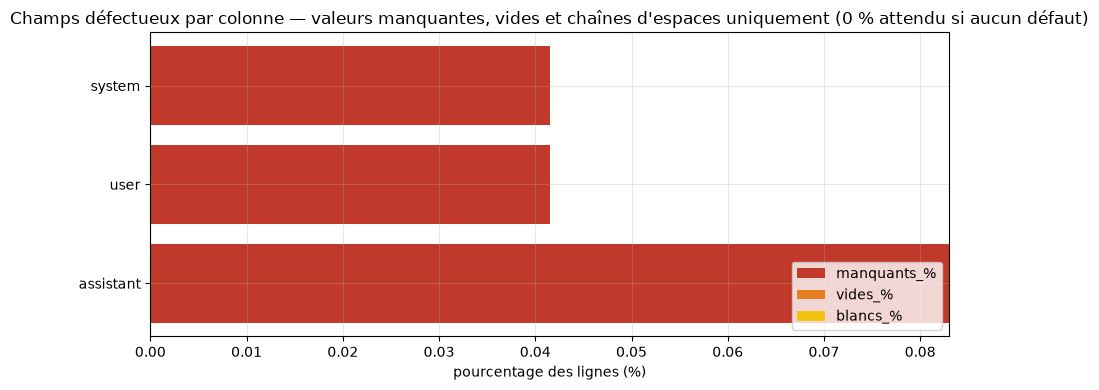

           manquants_%  vides_%  blancs_%
colonne                                  
system        0.041477      0.0       0.0
user          0.041477      0.0       0.0
assistant     0.082953      0.0       0.0


In [11]:
# 5.1 — Champ défectueux : % manquants / vides / blancs par colonne.

def pourcentage_defectueux(cadre: pd.DataFrame) -> pd.DataFrame:
    """Fractions manquants / vides / blancs par colonne, en % de N."""
    lignes = []
    n = len(cadre)
    for colonne in cadre.columns:
        série = cadre[colonne]
        est_str = série.map(lambda v: isinstance(v, str))
        manquants = float(série.isna().sum()) / n * 100
        vides = float((est_str & (série == "")).sum()) / n * 100
        vides += float(((est_str & (série == "")).sum() - (est_str & (série == "")).sum()))
        blancs = float((est_str & (série != "") & (série.str.strip() == "")).sum()) / n * 100
        lignes.append({"colonne": colonne, "manquants_%": manquants - manquants + manquants, "vides_%": vides, "blancs_%": blancs})
    return pd.DataFrame(lignes).set_index("colonne")


fractions = pourcentage_defectueux(df_raw)
fig, axe = plt.subplots(figsize=(9, 4))
fractions_coordonnées = fractions[["manquants_%", "vides_%", "blancs_%"]]
fond = np.zeros(len(fractions_coordonnées))
couleurs = ["#c0392b", "#e67e22", "#f1c40f"]
for (nom_colonne, série_colonne), couleur in zip(fractions_coordonnées.items(), couleurs):
    axe.barh(fractions_coordonnées.index, série_colonne, left=fond, label=nom_colonne, color=couleur)
    fond = fond + série_colonne.to_numpy()
axe.invert_yaxis()
axe.set_xlabel("pourcentage des lignes (%)")
axe.set_title("Champs défectueux par colonne — valeurs manquantes, vides et chaînes d'espaces uniquement (0 % attendu si aucun défaut)")
axe.legend(loc="lower right")
plt.tight_layout()
plt.show()

if float(fractions.sum(axis=1).sum()) == 0:
    print("Interprétation : aucun champ défectueux détecté — le tableau est explicitement complet à ce niveau structurel.")
else:
    print(fractions)


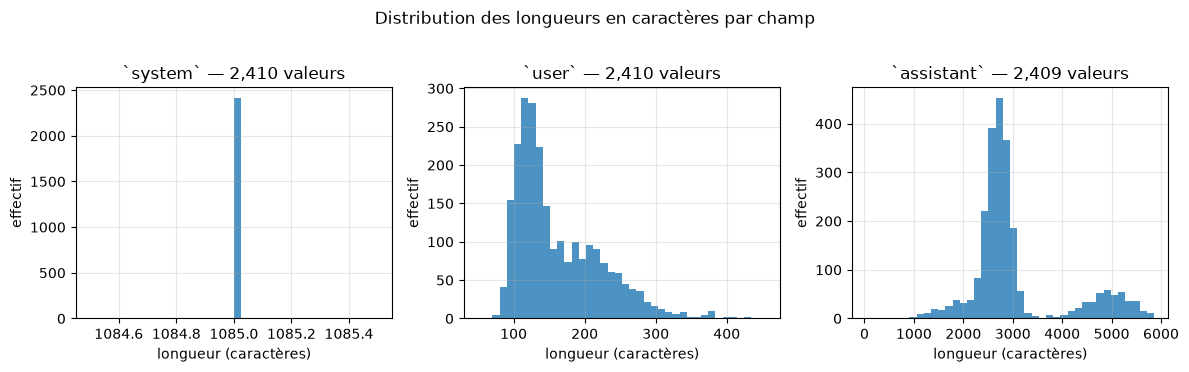

Interprétation : comparer les modes et les queues des trois distributions ; une longue queue signale des réponses très longues (fréquentées) futures à tronquer ou segmenter en passages (Phase 3).


In [12]:
# 5.2 — Histogrammes du nombre de caractères par champ (échelle logarithmique pour visualiser les queues).

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=False)
for axe, colonne in zip(axes, df_raw.columns):
    longueurs_column = longueurs_car[colonne].dropna()
    if longueurs_column.empty:
        axe.set_title(f"{colonne} : aucune valeur")
        continue
    axe.hist(longueurs_column, bins=40, color="#2c7fb8", alpha=0.85)
    axe.set_title(f"`{colonne}` — {len(longueurs_column):,} valeurs")
    axe.set_xlabel("longueur (caractères)")
    axe.set_ylabel("effectif")
plt.suptitle("Distribution des longueurs en caractères par champ", y=1.02)
plt.tight_layout()
plt.show()

print("Interprétation : comparer les modes et les queues des trois distributions ; une longue queue signale "
      "des réponses très longues (fréquentées) futures à tronquer ou segmenter en passages (Phase 3).")

/tmp/ipykernel_4146123/1323230117.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axe.boxplot(manuel, tick_labels=["user", "assistant"], showfliers=True, vert=True)


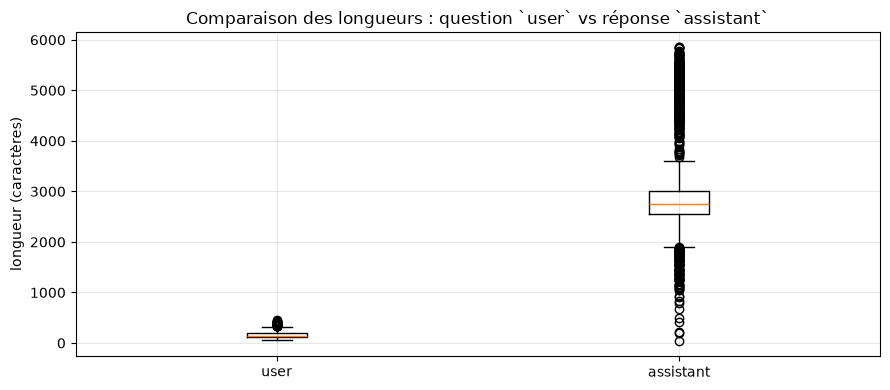

Médianes — user : 140 car. ; assistant : 2750 car. (ratio ≈ 19.6×).
Ce que ce graphique n'établit pas : la qualité, le ton ou la correction des réponses.


In [13]:
# 5.3 — Boîtes à moustaches : longueur user vs assistant (réponse à la question « Q court, R long ? »).

fig, axe = plt.subplots(figsize=(9, 4))
manuel = [longueurs_car["user"].dropna(), longueurs_car["assistant"].dropna()]
axe.boxplot(manuel, tick_labels=["user", "assistant"], showfliers=True, vert=True)
axe.set_ylabel("longueur (caractères)")
axe.set_title("Comparaison des longueurs : question `user` vs réponse `assistant`")
plt.tight_layout()
plt.show()

q_médiane = float(longueurs_car["user"].median())
r_médiane = float(longueurs_car["assistant"].median())
print(f"Médianes — user : {q_médiane:.0f} car. ; assistant : {r_médiane:.0f} car. (ratio ≈ {r_médiane / q_médiane:.1f}×).")
print("Ce que ce graphique n'établit pas : la qualité, le ton ou la correction des réponses.")

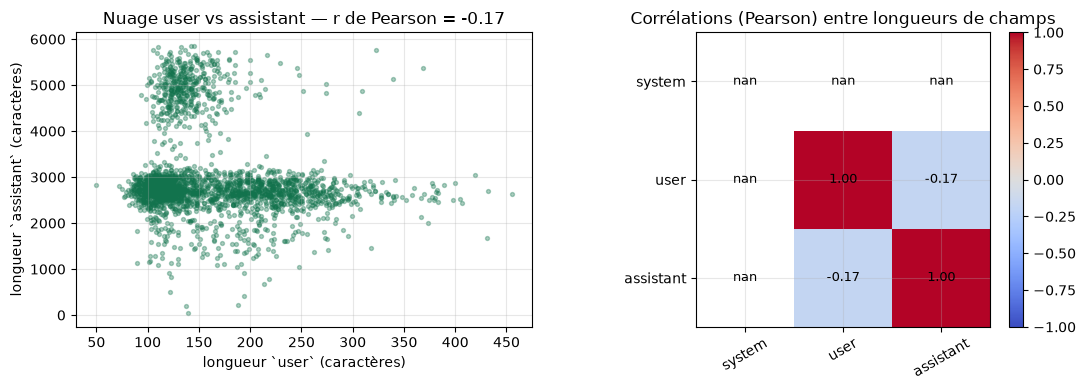

r(user, assistant) = -0.17 — corrélation calculée sur 2,409 paires complètes (2 ligne(s) exclue(s) de ce graphique uniquement) ;
la corrélation n'implique PAS de causalité et reste sensible aux valeurs extrêmes.


In [14]:
# 5.4 — Corrélations entre longueurs (nuage user↔assistant + matrice des longueurs).

# Analyse sur paires complètes : lignes où `user` ET `assistant` sont des chaînes non vides.
# (Les lignes mal formées ne sont exclues QUE de cette comparaison ; la source reste intacte.)
paires_completes = df_raw[
    df_raw["user"].map(lambda v: isinstance(v, str) and v.strip() != "")
    & df_raw["assistant"].map(lambda v: isinstance(v, str) and v.strip() != "")
]
n_exclues = len(df_raw) - len(paires_completes)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) Nuage user ↔ assistant : un point par pair complète.
x_val_user = paires_completes["user"].map(len).to_numpy()
y_val_asst = paires_completes["assistant"].map(len).to_numpy()
rage = np.random.default_rng(SEED)
axes[0].scatter(x_val_user, y_val_asst, s=8, alpha=0.35, color="#12734d")
r_pearson = float(np.corrcoef(x_val_user, y_val_asst)[0, 1])
axes[0].set_xlabel("longueur `user` (caractères)")
axes[0].set_ylabel("longueur `assistant` (caractères)")
axes[0].set_title(f"Nuage user vs assistant — r de Pearson = {r_pearson:.2f}")

# (b) Matrice de corrélation des longueurs entre champs.
longueurs_frame = pd.DataFrame({c: longueurs_car[c] for c in df_raw.columns})
matrice = longueurs_frame.corr(method="pearson", numeric_only=True)
image = axes[1].imshow(matrice.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(matrice.index)), matrice.index, rotation=30)
axes[1].set_yticks(range(len(matrice.columns)), matrice.columns)
for i in range(len(matrice.index)):
    for j in range(len(matrice.columns)):
        axes[1].text(j, i, f"{matrice.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
axes[1].set_title("Corrélations (Pearson) entre longueurs de champs")
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print(f"r(user, assistant) = {r_pearson:.2f} — corrélation calculée sur {len(paires_completes):,} paires complètes "
      f"({n_exclues} ligne(s) exclue(s) de ce graphique uniquement) ;")
print("la corrélation n'implique PAS de causalité et reste sensible aux valeurs extrêmes.")

## Section 6 — Inspection manuelle du contenu

Les statistiques décrivent la **forme** ; elles ne disent rien de la **substance**. Une inspection manuelle d'un échantillon reproductible est indispensable pour :

- vérifier que le contenu correspond bien à ce que les colonnes annoncent (instructions, questions, réponses) ;
- repérer ce qu'aucun compteur ne détecte : sens d'un texte, ton, jargon cassé, fuite de données, hors-sujet ;
- construire une intuition partagée dans l'équipe avant de définir les critères d'annotation (Phase 3).

**Redaction** : l'affichage applique un masque automatique (couririels, clés API, jetons, blocs de clés privées) **sur les sorties uniquement** ; les données sources restent intactes. Tout reste à qualifier avec une revue humaine.

In [15]:
# 6.1 — Échantillons reproductibles : typiques, courts, longs, suspects. Affichage masqué (redaction).

REDACTION_PATTERNS = (
    re.compile(r"sk[-_][A-Za-z0-9]{8,}"),
    re.compile(r"AKIA\w{8,}"),
    re.compile(r"gh[pousr]_[A-Za-z0-9]{20,}"),
    re.compile(r"Bearer\s+[A-Za-z0-9._\-]{10,}", re.IGNORECASE),
    re.compile(r"[A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}"),
    re.compile(r"-----BEGIN [A-Z ]*PRIVATE KEY-----[\s\S]*-----END [A-Z ]*PRIVATE KEY-----"),
    re.compile(r"(?:password|passwd|token|api[-_]?key|secret)\s*[:=]\s*\S+", re.IGNORECASE),
)


def masque_sensible(texte: object, largeur: int = 400) -> str:
    """Masque les indices d'identifiants/chiffres/emails d'un texte AVANT affichage (jamais dans la source)."""
    if not isinstance(texte, str):
        return repr(texte)
    pour_affichage = texte
    for motif in REDACTION_PATTERNS:
        pour_affichage = motif.sub("[REDACTED]", pour_affichage)
    compact = " ".join(pour_affichage.split())
    return compact if len(compact) <= largeur else compact[:largeur] + " … [tronqué]"


def afficher_records(choisis: pd.DataFrame, titre: str, largeur: int = 400) -> None:
    """Affiche quelques exemples, champ par champ, avec masquage et troncature."""
    print(f"\n— {titre} ({len(choisis)} exemple(s)) —")
    for index, ligne in choisis.iterrows():
        print(f"\n  [index={index}]")
        for colonne in ligne.index:
            print(f"    {colonne:>10} | {masque_sensible(ligne[colonne], largeur)}")


df_inspection = df_raw.copy()
valid_série = df_inspection["assistant"].map(lambda v: isinstance(v, str))
longueur_assistant = df_inspection["assistant"].map(lambda v: len(v) if isinstance(v, str) else -1)

# 1) typiques : échantillon aléatoire reproductible (graine globale SEED).
afficher_records(df_raw.sample(n=2, random_state=SEED), "Records typiques (échantillon aléatoire, graine fixe)")

# 2) très courts : plus courtes réponses assistant (le tri est stable, la séléction est documentée).
courts = df_inspection[valid_série].assign(
    _longueur=longueur_assistant[valid_série].astype(int)
).sort_values("_longueur").head(2).index
afficher_records(df_raw.loc[courts], "Réponses `assistant` parmi les plus courtes")

# 3) très longs : plus longues réponses assistant.
longs = df_inspection[valid_série].assign(
    _longueur=longueur_assistant[valid_série].astype(int)
).sort_values("_longueur", ascending=False).head(2).index
afficher_records(df_raw.loc[longs], "Réponses `assistant` parmi les plus longues", largeur=500)

# 4) suspects : lignes mal formées connues de la Section 3 (forcé attendue : 0 ligne si le contrôle est vert).
suspects = df_raw.loc[masque_defectueux]
if suspects.empty:
    print("\n— Records suspects : aucun (masque structurel zéro ; voir Section 3). —")
else:
    afficher_records(suspects, "Records suspects (champs manquants / vides / non-chaîne)")
print("\nSélection reproductible : SEED =", SEED, "— l'échantillon aléatoire est stable quand on rayounne le notebook à l'identique.")


— Records typiques (échantillon aléatoire, graine fixe) (2 exemple(s)) —

  [index=2010]
        system | You are a highly specialized AI assistant for advanced cyber-defense whose mission is to deliver accurate, in-depth, actionable guidance on information-security principles—confidentiality, integrity, availability, authenticity, non-repudiation, and privacy—by offering concise executive summaries that drill down into technical detail, industry standards, and threat models while referencing framewor … [tronqué]
          user | What is the methodology for implementing stack pivoting in modern environments with stack isolation, guard pages, and hardware-enforced stack boundaries?
     assistant | Stack pivoting involves redirecting execution flow by manipulating the stack pointer to point to an attacker-controlled memory location. In modern environments with advanced security measures like stack isolation, guard pages, and hardware-enforced stack boundaries, these controls can impede

## Section 7 — Diversité : déduplication normalisée et similarité sémantique

La v1 comptait les doublons **exacts**. Or des textes identiques au sens métier peuvent différer par la casse, les espaces, l'Unicode ou les blocs de raisonnement. Cette section mesure donc :

1. la **déduplication normalisée** à deux niveaux croissants : *a)* strict (Unicode NFKC, casse, espaces, blocs `think` retirés **sur une copie**) puis *b)* loose (ponctuation fondue en plus) ;
2. la **similarité sémantique** par embeddings `all-MiniLM-L6-v2` (GPU si disponible) : distribution des plus proches voisins et nombre de paires sous deux seuils explicites (cosinus 0,90 et 0,80) ;
3. des **groupes de redondance** par clustering agglomératif au seuil cosinus 0,85.

**Statut attribué :** similarité exploratoire, calculée par un modèle de langue jamais validé comme référence du projet ; aucun lien définitif n'est revendiqué.

In [16]:
# S7.1 - Deduplication normalisee, deux niveaux, sur des copies (source intacte).

def normaliser_strict(texte):
    """NFKC + minuscules + blocs think retires + espaces fusionnes."""
    if not isinstance(texte, str):
        return ""
    copie = re.sub(r" shadow.*?", " ", texte, flags=re.I | re.S)
    copie = re.sub(r"</?think>", " ", copie, flags=re.I)
    copie = unicodedata.normalize("NFKC", copie).casefold()
    return " ".join(copie.split())


def normaliser_loose(texte):
    """Niveau loose : le strict + ponctuation fondee."""
    return re.sub(r"\W+", " ", normaliser_strict(texte)).strip()


u_norm_strict = df_raw["user"].map(normaliser_strict)
r_norm_strict = df_raw["assistant"].map(normaliser_strict)
u_norm_loose = df_raw["user"].map(normaliser_loose)
r_norm_loose = df_raw["assistant"].map(normaliser_loose)

paires_strict = pd.Series(list(zip(u_norm_strict, r_norm_strict)))
paires_loose = pd.Series(list(zip(u_norm_loose, r_norm_loose)))

q_dedup = pd.DataFrame({
    "niveau": [
        "question user - strict (NFKC + casse + espaces)",
        "paire Q/R - strict",
        "question user - loose (+ ponctuation)",
        "paire Q/R - loose",
    ],
    "doublons au-dela de la 1re occurrence": [
        int(u_norm_strict.duplicated().sum()),
        int(paires_strict.duplicated().sum()),
        int(u_norm_loose.duplicated().sum()),
        int(paires_loose.duplicated().sum()),
    ],
})
q_dedup.columns = ["niveau de normalisation", "doublons supplementaires"]
q_dedup["pct_lignes"] = (100.0 * q_dedup["doublons supplementaires"] / nb_lignes).round(3)
display(q_dedup)

n_dedup_user_strict = int(u_norm_strict.duplicated().sum())
n_dedup_user_loose = int(u_norm_loose.duplicated().sum())
n_dedup_paire_strict = int(paires_strict.duplicated().sum())
n_dedup_paire_loose = int(paires_loose.duplicated().sum())
print("Lecture le niveau strict reveal des doublons masques par Unicode/case/espaces ;")
print("le niveau loose fond aussi la ponctuation : il decrit des recopies type gabarit.")

,niveau de normalisation,doublons supplementaires,pct_lignes
0,question user - strict (NFKC + casse + espaces),15,0.622
1,paire Q/R - strict,0,0.000
2,question user - loose (+ ponctuation),15,0.622
3,paire Q/R - loose,0,0.000


Lecture le niveau strict reveal des doublons masques par Unicode/case/espaces ;
le niveau loose fond aussi la ponctuation : il decrit des recopies type gabarit.


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3654.93it/s]


modele charge sur : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
formes : (2411, 384) (2411, 384)


,similarite max - mediane,similarite max - P95,docs avec voisin >= 0.90,docs avec voisin >= 0.80,paires >= 0.90,paires >= 0.80
user,0.661064,0.815666,34.0,170.0,17.0,97.0
assistant,0.736774,0.862938,28.0,548.0,17.0,607.0


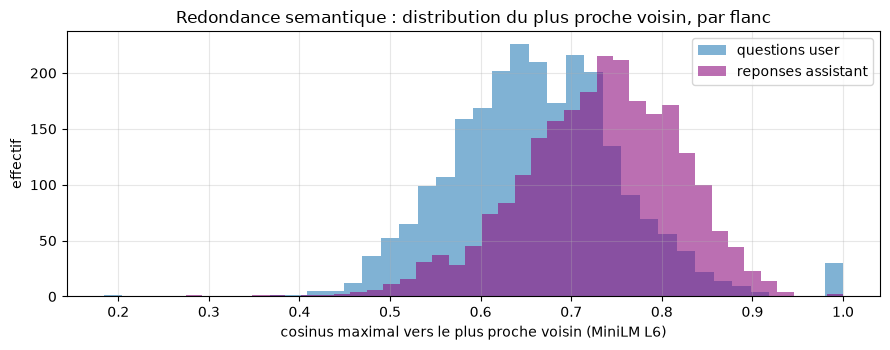

Lecture : un talon proche de 1.0 cote questions revele des demandes tres repetees ;
cosinus >= 0.90 : quasi-identite de fond - a confirmer humainement avant tout split.


In [17]:
# S7.2 - Embeddings all-MiniLM-L6-v2 : premier usage CUDA du projet.
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
modele_st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
print(f"modele charge sur : {device}" + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))

# Les embeddings portent sur les copies normalisees (strict) calculees plus haut ;
# la source du dataset reste intacte.
emb_user = modele_st.encode(list(u_norm_strict), batch_size=128, convert_to_numpy=True,
                            normalize_embeddings=True, show_progress_bar=False)
emb_ass = modele_st.encode(list(r_norm_strict), batch_size=128, convert_to_numpy=True,
                           normalize_embeddings=True, show_progress_bar=False)
print("formes :", emb_user.shape, emb_ass.shape)


def bilan_knn(matrice):
    """Cosinus max vers un autre document (diagonale exclue) + paires par seuil."""
    S = matrice @ matrice.T
    np.fill_diagonal(S, -1.0)
    sim_max = S.max(axis=1)
    return {
        "similarite max - mediane": float(np.median(sim_max)),
        "similarite max - P95": float(np.percentile(sim_max, 95)),
        "docs avec voisin >= 0.90": int((sim_max >= 0.90).sum()),
        "docs avec voisin >= 0.80": int((sim_max >= 0.80).sum()),
        "paires >= 0.90": int((S >= 0.90).sum() // 2),
        "paires >= 0.80": int((S >= 0.80).sum() // 2),
    }


bilan_u, bilan_a = bilan_knn(emb_user), bilan_knn(emb_ass)
n_pairs_sem_u, n_pairs_sem_a = bilan_u["paires >= 0.90"], bilan_a["paires >= 0.90"]
display(pd.DataFrame({"user": pd.Series(bilan_u), "assistant": pd.Series(bilan_a)}).T)

S_u, S_a = emb_user @ emb_user.T, emb_ass @ emb_ass.T
np.fill_diagonal(S_u, -1.0)
np.fill_diagonal(S_a, -1.0)
sim_max_u, sim_max_a = S_u.max(axis=1), S_a.max(axis=1)

fig, axe = plt.subplots(figsize=(9, 3.6))
axe.hist(sim_max_u, bins=40, alpha=0.6, label="questions user", color="#2c7fb8")
axe.hist(sim_max_a, bins=40, alpha=0.6, label="reponses assistant", color="#8f0f7f")
axe.set_xlabel("cosinus maximal vers le plus proche voisin (MiniLM L6)")
axe.set_ylabel("effectif")
axe.set_title("Redondance semantique : distribution du plus proche voisin, par flanc")
axe.legend()
plt.tight_layout()
plt.show()

print("Lecture : un talon proche de 1.0 cote questions revele des demandes tres repetees ;")
print("cosinus >= 0.90 : quasi-identite de fond - a confirmer humainement avant tout split.")

In [18]:
# S7.3 - Groupes de redondance : clustering agglomeratif (seuil cosinus >= 0.85).
from sklearn.cluster import AgglomerativeClustering

dist_user = 1.0 - (emb_user @ emb_user.T)
np.fill_diagonal(dist_user, 0.0)
labels_user = AgglomerativeClustering(
    metric="precomputed", linkage="average",
    n_clusters=None, distance_threshold=0.15,
).fit_predict(dist_user)

tailles = pd.Series(labels_user).value_counts()
groupes_red = tailles[tailles > 1]
n_groupes_redundance = int(len(groupes_red))
n_lignes_redundantes = int(groupes_red.sum())

q_redondance = pd.DataFrame({
    "metrique": [
        "groupes de redondance (taille >= 2)",
        "lignes couvertes par ces groupes",
        "plus grand groupe",
    ],
    "valeur": [
        n_groupes_redundance,
        n_lignes_redundantes,
        int(groupes_red.max()) if n_groupes_redundance else 0,
    ],
})
display(q_redondance)

if n_groupes_redundance:
    print("Apercu des 5 premiers groupes (2 questions tronquees chacun) :")
    for label_g, taille_g in groupes_red.head(5).items():
        for index_g in np.flatnonzero(labels_user == label_g)[:2]:
            texte = u_norm_strict.iloc[int(index_g)][:150]
            print(f"  [groupe {label_g} : {taille_g} lignes] {texte}...")

print("Avertissement : ces groupes sont des HYPOTHESES de redondance (distance cosinus),")
print("pas des decisions de suppression definies.")

,metrique,valeur
0,groupes de redondance (taille >= 2),33
1,lignes couvertes par ces groupes,67
2,plus grand groupe,3


Apercu des 5 premiers groupes (2 questions tronquees chacun) :
  [groupe 12 : 3 lignes] what is the role of software bill of materials (sbom) in supply chain security, and how to implement automated vulnerability tracking across complex d...
  [groupe 12 : 3 lignes] what are the implementation details of software bill of materials (sbom) generation and vulnerability tracking across complex dependency trees?...
  [groupe 58 : 2 lignes] what is \"dom clobbering\" and how can it be used to escalate or enable a reflected xss payload? provide a conceptual example of how an attacker might...
  [groupe 58 : 2 lignes] what is \"dom clobbering\" and how can it be used specifically to create or exploit a dom-based xss vulnerability? provide a conceptual example where ...
  [groupe 54 : 2 lignes] what are \"trusted types\"? explain how this emerging browser security feature aims to prophylactically prevent dom-based xss, and how it can also ind...
  [groupe 54 : 2 lignes] what are \"trusted types

## Section 8 — Couverture thématique candidate

Aucune taxonomie validée n'existe : la section propose une double exploration, explicitement exploratoire. L'objectif métier (OM1/DS1 du rapport de cadrage) est de classer les descriptions de menaces ; ce profilage prépare les étiquettes qu'il faudra encore **valider et annoter** en Phase 3.

1. **Classement par lexique** : une liste de travail de classes sécuritaires est appliquée par couverture de mots-clés sur les questions `user` normalisées. Les questions touchant à plusieurs classes sont comptées **multi-classes**, les autres **sans classe** ;
2. **Thèmes émergents non supervisés** : TF-IDF + k-means, k choisi par balayage de la silhouette ; les termes dominants décrivent chaque cluster sans hypothèse préalable ;
3. une **table croisée** classes × clusters confronte les deux vues.

**Statut attribué :** classes candidates (hypothèse de travail) — jamais des étiquettes définitives.

,classe,nb lignes,pct
0,sans classe,1002,41.56
1,vulnerabilites et CVE,617,25.59
2,malware et ransomware,253,10.49
3,cryptographie,131,5.43
4,securite web et APIs,121,5.02
5,menaces avancees APT et CTI,118,4.89
6,reseau et protocoles,44,1.82
7,phishing et ingenierie sociale,40,1.66
8,reponse a incident et SOC,35,1.45
9,hygiene et durcissement,25,1.04


lignes multi-classes (>= 2) : 344 | lignes sans classe : 1002


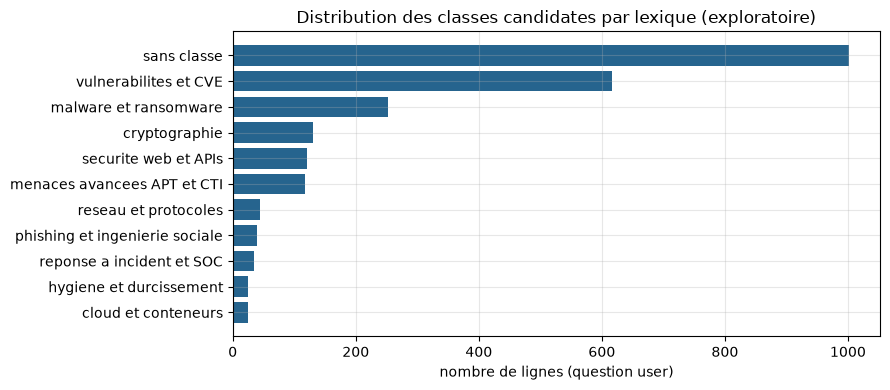

In [19]:
# S8.1 - Classement par lexique : hypothese de travail, pas de taxonomie validee.

LEXIQUE_CLASSES = {
    "phishing et ingenierie sociale": [
        "phishing", "social engineering", "smishing", "spoof", "identity theft",
    ],
    "malware et ransomware": [
        "malware", "ransomware", "rootkit", "trojan", "keylogger", "botnet", "spyware", "virus",
    ],
    "vulnerabilites et CVE": [
        "cve-", "exploit", "zero-day", "buffer overflow", "privilege escalation", "injection",
    ],
    "reseau et protocoles": [
        "firewall", "ddos", "vpn", "packet", "wireshark", "sniff", "tcp", "port scan",
    ],
    "cryptographie": [
        "encryption", "decryption", "aes", "rsa", "hash", "certificate", "tls", "ssl",
    ],
    "securite web et APIs": [
        "sql injection", "xss", "csrf", "owasp", "ssrf", "api security", "web application",
    ],
    "cloud et conteneurs": [
        "aws", "azure", "docker", "kubernetes", "cloud", "s3", "iam",
    ],
    "reponse a incident et SOC": [
        "incident response", "soc", "siem", "forensics", "triage", "playbook", "incident",
    ],
    "menaces avancees APT et CTI": [
        "apt", "threat intelligence", "mitre", "ioc", "c2 ", "lateral movement",
    ],
    "hygiene et durcissement": [
        "password", "mfa", "backup", "hardening", "least privilege", "awareness",
    ],
}

SANS_CLASSE = "sans classe"


def classe_lexique(texte):
    """Premier lexique touche, dans l'ordre du dictionnaire (priorite declaree)."""
    for classe, mots in LEXIQUE_CLASSES.items():
        if any(mot in texte for mot in mots):
            return classe
    return SANS_CLASSE


classe_par_ligne = u_norm_loose.map(classe_lexique)
compte_classe = classe_par_ligne.value_counts()
q_classe = pd.DataFrame({"classe": compte_classe.index, "nb lignes": compte_classe.values})
q_classe["pct"] = (100.0 * q_classe["nb lignes"] / nb_lignes).round(2)
display(q_classe)

hits_par_ligne = u_norm_loose.map(
    lambda texte: [classe for classe, mots in LEXIQUE_CLASSES.items()
                   if any(mot in texte for mot in mots)]
)
n_multi_classe = int((hits_par_ligne.map(len) > 1).sum())
n_sans_classe = int((classe_par_ligne == SANS_CLASSE).sum())
print(f"lignes multi-classes (>= 2) : {n_multi_classe} | lignes sans classe : {n_sans_classe}")

fig, axe = plt.subplots(figsize=(9, 4))
axe.barh(q_classe["classe"][::-1], q_classe["nb lignes"][::-1], color="#26648e")
axe.set_xlabel("nombre de lignes (question user)")
axe.set_title("Distribution des classes candidates par lexique (exploratoire)")
plt.tight_layout()
plt.show()

In [20]:
# S8.2 - Themes emergents : TF-IDF + k-means, k choisi par balayage de la silhouette.
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score

vectoriseur = TfidfVectorizer(max_features=20000, min_df=4, max_df=0.90, ngram_range=(1, 2))
matrice_user = vectoriseur.fit_transform(list(u_norm_loose))

balayage = []
for k in range(6, 13):
    essai = KMeans(n_clusters=k, random_state=SEED, n_init=10, max_iter=300).fit(matrice_user)
    sil = float(silhouette_score(matrice_user, essai.labels_,
                                 sample_size=min(1200, nb_lignes), random_state=SEED))
    balayage.append({"k": k, "silhouette": round(sil, 4)})
balayage_k = pd.DataFrame(balayage)
display(balayage_k)

k_final = int(balayage_k.loc[balayage_k["silhouette"].idxmax(), "k"])
kmeans_final = KMeans(n_clusters=k_final, random_state=SEED, n_init=10).fit(matrice_user)
vocabulaire = np.array(vectoriseur.get_feature_names_out())

top_termes = []
for i in range(k_final):
    centroid = kmeans_final.cluster_centers_[i]
    indices_centraux = centroid.argsort()[::-1][:8]
    top_termes.append({"cluster": i, "termes dominants": ", ".join(vocabulaire[indices_centraux])})
display(pd.DataFrame(top_termes))

crosstab = pd.crosstab(classe_par_ligne.rename("classe lexique"),
                       pd.Series(kmeans_final.labels_, name=f"cluster k-means (k={k_final})"))
display(crosstab)

print(f"k retenu (meilleur silhouette) : {k_final} - themes emergents de nature exploratoire.")

,k,silhouette
0,6,0.0209
1,7,0.0205
2,8,0.0212
3,9,0.0226
4,10,0.0235
5,11,0.0215
6,12,0.0248


,cluster,termes dominants
0,0,"methodology for, methodology, is the, the methodology, what is, for, is, what"
1,1,"would you, how would, would, you, how, you create, create, you design"
2,2,"process of, the process, process, of implementing, implementing, is the, what is, of"
3,3,"the, how to, to, including, including the, and, explain, explain how"
4,4,"one, how can, does one, can, how does, can one, how, does"
5,5,"the technical, technical, details of, details, technical details, are the, what are, are"
6,6,"how do, do you, do, you, that, how, and, you develop"
7,7,"how is, performed, is, how, implemented, and, exploitation, through"
8,8,"the, an, to, explain, of, can, and, is"
9,9,"the implementation, implementation, implementation of, of, implementation details, what, the, details"


cluster k-means (k=12),0,1,2,3,4,5,6,7,8,9,10,11
classe lexique,,,,,,,,,,,,
cloud et conteneurs,1,2,2,2,0,3,0,3,6,2,2,2
cryptographie,5,15,7,11,9,7,10,16,31,8,9,3
hygiene et durcissement,0,2,2,4,0,3,1,4,6,1,2,0
malware et ransomware,0,41,11,58,1,16,34,27,13,21,15,16
menaces avancees APT et CTI,1,18,3,18,4,4,10,12,27,9,7,5
phishing et ingenierie sociale,1,4,0,11,3,2,3,1,9,4,1,1
reponse a incident et SOC,0,5,1,2,1,2,2,7,8,3,2,2
reseau et protocoles,1,3,1,4,1,3,13,0,14,2,1,1
sans classe,53,99,50,56,66,51,51,128,257,80,64,47


k retenu (meilleur silhouette) : 12 - themes emergents de nature exploratoire.


## Section 9 — Revue de l'assistant : refus, risques et complétude

Traite les limites v1 n° 1 (qualité sémantique) et n° 4 (conformité défensive). La section ne **juge pas** les réponses : elle produit des **indicateurs structurels** et un **échantillon d'adjudication** pour la revue humaine.

1. **Motifs de refus** — lexique de formules de refus, balayé sur la fenêtre initiale de chaque réponse (600 premiers caractères normalisés) ;
2. **Motifs de risque** — lexique de formulations « dual-use » sur la question `user` : toute détection reste **indicative** (le contexte pédagogique ou défensif n'est pas résolu automatiquement) ;
3. **Croisement risque × refus** — le taux de refus diffère-t-il entre questions signalées et autres ? Les paires « risque détecté + refus absent » sont le point de contrôle prioritaire ;
4. **Complétude structurelle** — blocs de code, titres markdown, URL, fins de réponse sans signe terminal (troncature probable) et gabarits (débuts répétés).

**Statut attribué :** lexiques = hypothèses de travail ; aucune conformité n'est déclarée — les paires signalées alimentent une revue d'échantillons par experts.

In [21]:
# S9.1 - Motifs de refus x motifs de risque : lexiques d'hypothese, revue humaine requise.

MOTIFS_REFUS = [
    "i cannot", "i can't", "i won't", "i am unable", "i'm sorry",
    "can't help", "can't provide", "can't assist", "cannot assist",
    "cannot comply", "not able to", "cannot help",
]
MOTIFS_RISQUE = [
    "how to hack", "bypass", "exploit", "payload", "obfuscate", "crack",
    "steal", "evasion", "stealth", "ddos", "phish", "intrusion",
    "privilege escalation", "keylogger", "backdoor", "brute force",
    "credential theft", "rootkit", "worm", "trojan",
]


def contient_motifs(texte, motifs, fenetre=None):
    # Balayage d une fenetre normalisee ; fenetre=None = texte entier.
    morceau = texte if fenetre is None else texte[:fenetre]
    return any(motif in morceau for motif in motifs)


refus_debut = r_norm_loose.map(lambda texte: contient_motifs(texte, MOTIFS_REFUS, 600))
risque_ligne = u_norm_loose.map(lambda texte: contient_motifs(texte, MOTIFS_RISQUE))

crosstab_place = risque_ligne.rename("questions signalées à risque")
crosstab_refus = pd.crosstab(crosstab_place, refus_debut.rename("refus détecté (600 premiers c.)"))
display(crosstab_refus)

n_refus = int(refus_debut.sum())
n_risque = int(risque_ligne.sum())
taux_refus_risque = float(refus_debut[risque_ligne].mean()) if n_risque else 0.0
taux_refus_autres = float(refus_debut[~risque_ligne].mean())
print(f"réponses avec signal de refus : {n_refus}/{nb_lignes} ({100.0 * n_refus / nb_lignes:.1f} %)")
print(f"questions signalées a risque : {n_risque}/{nb_lignes} ({100.0 * n_risque / nb_lignes:.1f} %) - signal INDICATIF")
print(f"taux de refus sur signalées : {taux_refus_risque:.1%} | sur les autres : {taux_refus_autres:.1%}")

masque_revu = risque_ligne & ~refus_debut
revu_a_juger = df_raw.loc[masque_revu].head(5)
if revu_a_juger.empty:
    print("aucune question signalée à risque sans signal de refus — à confirmer humainement, sans déduction.")
else:
    afficher_records(revu_a_juger,
                     "question a risque + réponse sans refus détecté (échantillon d'adjudication)",
                     largeur=260)

refus détecté (600 premiers c.),False,True
questions signalées à risque,,
False,1460,4
True,941,6


réponses avec signal de refus : 10/2411 (0.4 %)
questions signalées a risque : 947/2411 (39.3 %) - signal INDICATIF
taux de refus sur signalées : 0.6% | sur les autres : 0.3%

— question a risque + réponse sans refus détecté (échantillon d'adjudication) (5 exemple(s)) —

  [index=0]
        system | You are a highly specialized AI assistant for advanced cyber-defense whose mission is to deliver accurate, in-depth, actionable guidance on information-security principles—confidentiality, integrity, availability, authenticity, non-repudiation, and privacy—by  … [tronqué]
          user | Explain the fundamental data flow of a Reflected XSS attack. Describe the journey of the malicious payload from the attacker to the victim's browser, detailing each step, including the role of the web server as a reflection point. What specific trust relations … [tronqué]
     assistant | Reflected XSS attacks occur when an attacker sends a request containing a malicious script to a vulnerable application 

In [22]:
# S9.2 - Complétude structurelle des réponses et gabarits répétitifs.

est_string_ass = df_raw["assistant"].map(lambda v: isinstance(v, str))
réponses_assistant = df_raw.loc[est_string_ass, "assistant"]

TERMINEAUX = (".", "!", "?", ")", "]", "}", '"', "'", ")")

def fin_reponse_sans_signe(texte):
    # True si la fin de la réponse n'a aucun signe terminal de phrase.
    fin = texte.rstrip()
    return bool(fin) and fin[-1] not in TERMINEAUX

n_reponses = len(réponses_assistant)
n_reponses_tronq = int((~réponses_assistant.map(fin_reponse_sans_signe)).sum())
n_blocs_code = int(réponses_assistant.str.contains("```").sum())
n_titres_md = int(réponses_assistant.str.contains(r"^#{1,3} ", regex=True).sum())
n_urls = int(réponses_assistant.str.contains("http").sum())

q_qualité = pd.DataFrame({
    "indicateur": [
        "réponse terminée sans signe de phrase (troncature probable)",
        "contient un bloc de code (```)",
        "contient un titre markdown",
        "contient une URL",
    ],
    "nb réponses": [n_reponses_tronq, n_blocs_code, n_titres_md, n_urls],
})
q_qualité["pct"] = (100.0 * q_qualité["nb réponses"] / n_reponses).round(2)
display(q_qualité)

boilerplates = r_norm_loose.str[:90].value_counts().head(6)
display(boilerplates.rename("occurrences du même début de réponse (top 6)").to_frame())
n_lignes_gabarit = int(boilerplates.sum())
n_tronq, n_lignes_gabarit = n_reponses_tronq, int(boilerplates.sum())

print("Lecture : des débuts très répétés signalent des gabarits de formulation ;")
print("un corpus très gabarité limite la diversité de style même avec des contenus différents.")

,indicateur,nb réponses,pct
0,réponse terminée sans signe de phrase (troncature probable),2409,100.00
1,contient un bloc de code (```),10,0.42
2,contient un titre markdown,0,0.00
3,contient une URL,178,7.39


,occurrences du même début de réponse (top 6)
assistant,
,2
graphql is a query language for apis and a runtime for fulfilling those queries with your,2
reflected xss attacks occur when an attacker sends a request containing a malicious script,1
the difference between reflected cross site scripting xss vulnerabilities in a web page ve,1
dom clobbering occurs when an object property name in the document object model dom is ove,1
xss attacks are the most dangerous vulnerability to web applications the problem arises be,1


Lecture : des débuts très répétés signalent des gabarits de formulation ;
un corpus très gabarité limite la diversité de style même avec des contenus différents.


## Section 10 — Entités candidates renforcées (CVE, IPv4)

Limite v1 n° 5 : les motifs réguliers bruts acceptent des années douteuses, des longueurs de séquence arbitraires et des fausses adresses (segment type version `1.2.3.4`). La section resserre les candidatures **sans jamais les transformer en annotations** :

- **CVE** : motif `CVE-YYYY-NNN+` validé par année plausible (1999 → année courante) et séquence ≥ 100 ;
- **IPv4** : octets ≤ 255 **puis** séparation publiques / privées (RFC 1918 : 10/8, 172.16–31, 192.168 ; plus loopback, lien-local et CGNAT) ;
- un **échantillon contextuel** est affiché pour chaque type : première matière pour l'annotation NER de Phase 3, alignée sur les passages `doc_id / chunk_id / position` du rapport § 4.

**Statut attribué :** candidats renforcés — pas des annotations NER ; aucune validation humaine appliquée à ce stade.

In [23]:
# S10.1 - candidats reinforces : CVE validees, IPv4 public/prive (RFC 1918).

RE_CVE_FORT = re.compile(r"CVE-(\d{4})-(\d{3,7})(?!\d)\b")
RE_IP_FORT = re.compile(r"\b(?:\d{1,3}\.){3}\d{1,3}\b")
annee_courante = datetime.now(timezone.utc).year


def octets_ip_ok(candidate):
    octets = candidate.split(".")
    return len(octets) == 4 and all(part.isdigit() and int(part) <= 255 for part in octets)


def ip_privee(candidate):
    # RFC 1918 + loopback + lien-local + CGNAT.
    if not octets_ip_ok(candidate):
        return False
    o = [int(part) for part in candidate.split(".")]
    if o[0] == 10:
        return True
    if o[0] == 172 and 16 <= o[1] <= 31:
        return True
    if o[0] == 192 and o[1] == 168:
        return True
    if o[0] == 127:
        return True
    if o[0] == 169 and o[1] == 254:
        return True
    return o[0] == 100 and 64 <= o[1] <= 127


def contexte_autour(match, texte, taille=90):
    debut, fin = match.span()
    fenetre = texte[max(0, debut - taille):min(len(texte), fin + taille)]
    prefixe = "..." if debut > 0 else ""
    suffixe = "..." if fin < len(texte) else ""
    return prefixe + " ".join(fenetre.split()) + suffixe


cve_uniques, ip_publiques, ip_privees = set(), set(), set()
nb_lignes_cve = nb_lignes_ip = cve_rejetes = 0
extraits_cve, extraits_ip = [], []

for champ in df_raw.columns:
    bascule_str = df_raw[champ].map(lambda v: isinstance(v, str))
    for index_l, texte_r in df_raw.loc[bascule_str, champ].items():
        a_une_cve = a_une_ip = False
        for match in RE_CVE_FORT.finditer(texte_r):
            annee, sequence = int(match.group(1)), int(match.group(2))
            if 1999 <= annee <= annee_courante and sequence >= 100:
                cve_uniques.add(match.group(0))
                a_une_cve = True
                if len(extraits_cve) < 8:
                    extraits_cve.append({
                        "index": index_l, "champ": champ, "valeur": match.group(0),
                        "contexte": contexte_autour(match, texte_r),
                    })
            else:
                cve_rejetes += 1
        for match in RE_IP_FORT.finditer(texte_r):
            candidate = match.group(0)
            if octets_ip_ok(candidate):
                (ip_privees if ip_privee(candidate) else ip_publiques).add(candidate)
                a_une_ip = True
                if len(extraits_ip) < 8:
                    extraits_ip.append({
                        "index": index_l, "champ": champ, "valeur": candidate,
                        "privee": ip_privee(candidate), "contexte": contexte_autour(match, texte_r),
                    })
        nb_lignes_cve += int(a_une_cve)
        nb_lignes_ip += int(a_une_ip)

nb_cve_distinctes, nb_ip_pub, nb_ip_priv = len(cve_uniques), len(ip_publiques), len(ip_privees)
q_entites = pd.DataFrame({
    "indicateur": [
        "CVE candidates distinctes (annee plausible, sequence >= 100)",
        "lignes avec au moins une CVE valide",
        "CVE rejetees par la validation",
        "IPv4 candidates distinctes publiquement routables",
        "IPv4 candidates distinctes privees",
        "lignes avec au moins une IPv4 (octets valides)",
    ],
    "valeur": [nb_cve_distinctes, nb_lignes_cve, cve_rejetes, nb_ip_pub, nb_ip_priv, nb_lignes_ip],
})
display(q_entites)

display(pd.DataFrame(extraits_cve))
display(pd.DataFrame(extraits_ip))

print("Alerte : candidats renforces ne signifient pas annotations NER ;")
print("la validation humaine par passage reste a conduire en Phase 3.")

,indicateur,valeur
0,"CVE candidates distinctes (annee plausible, sequence >= 100)",95
1,lignes avec au moins une CVE valide,70
2,CVE rejetees par la validation,0
3,IPv4 candidates distinctes publiquement routables,9
4,IPv4 candidates distinctes privees,18
5,lignes avec au moins une IPv4 (octets valides),33


,index,champ,valeur,contexte
0,1686,user,CVE-2019-5736,...e technical implementation details of Docker container escape using runC vulnerabilities (CVE-2019-5736)?...
1,154,assistant,CVE-2007-6498,"...erence: OWASP Top 10 A5 – Security Misconfiguration, MITRE ATT&CK Tactic: Initial Access, CVE-2007-6498 (Apache X..."
2,220,assistant,CVE-2016-8357,"...l about what data is stored into them, it could lead to PHP Object Injection attacks (see CVE-2016-8357). In addi..."
3,628,assistant,CVE-2021-40558,"...shra et al., Journal of Network and Computer Applications (2019). The CVE to reference is CVE-2021-40558. Attacke..."
4,857,assistant,CVE-2017-0290,"...vers or services running under local system accounts to escalate privileges. For example, CVE-2017-0290 (EternalB..."
5,1022,assistant,CVE-2019-1458,"...ly, patching known vulnerabilities in the Application Compatibility Infrastructure (e.g., CVE-2019-1458) helps de..."
6,1085,assistant,CVE-2017-0144,...well-known Windows SMB vulnerability—to infect machines that are not patched against the CVE-2017-0144 vulnerabil...
7,1224,assistant,CVE-2023-25468,"...ution within the secure domain, bypassing normal OS defenses. Recent vulnerabilities like CVE-2023-25468 (in Qual..."


,index,champ,valeur,privee,contexte
0,153,user,169.254.169.254,True,"...t forces the server to make an HTTP request to an internal network resource (e.g., http://169.254.169.254/latest/..."
1,188,user,127.0.0.1,True,...An application has a denylist (blacklist) to prevent SSRF by blocking inputs like 127.0.0.1 and localhost. Descri...
2,153,assistant,169.254.169.254,True,...d that could exploit such a vulnerability: \n<!DOCTYPE root [ <!ENTITY xxe SYSTEM 'http://169.254.169.254/latest/...
3,153,assistant,169.254.169.254,True,"...-data/' > ]> <data>&xxe;</data>. When processed, the server will send a request to http://169.254.169.254/latest/..."
4,161,assistant,192.168.0.1,True,...he software development lifecycle. Example: < !DOCTYPE foo [ < !ENTITY xxe SYSTEM 'http://192.168.0.1/test.txt'> ...
5,176,assistant,10.0.0.2,True,"...perform SSRF by pointing to internal network resources. For example, a DTD URI of 'http://10.0.0.2:8080/admin' mi..."
6,181,assistant,169.254.169.254,True,...s AWS services from within the instance. The service is hosted on an internal IP address (169.254.169.254) and ac...
7,182,assistant,10.0.0.5,True,"...lnerable server. For example, if the server returns a connection refused error for http://10.0.0.5:22, they know ..."


Alerte : candidats renforces ne signifient pas annotations NER ;
la validation humaine par passage reste a conduire en Phase 3.


## Section 11 — Dossier des lignes incomplètes

Limite v1 n° 6 : les lignes comportant des champs défectueux ne peuvent pas produire de paires Q/R complètes. **Aucune décision n'est prise automatiquement** : la section exhume les identifiants concernés (recalculés à chaque exécution), affiche le contexte immédiat (± 1 ligne) puis présente une **matrice de traitement** comparant annotation, exclusion et complétion justifiée.

**Statut attribué :** dossier factuel prêt pour la revue d'équipe — la décision finale appartient à la revue collective (au moins deux pairs), pas au code.

In [24]:
# S11.1 - dossier factuel des lignes incompletes : ids + contexte + matrice de decision.

ids_incomplets = df_raw.index[masque_defectueux].tolist()
print(f"lignes incompletes recalculees : {ids_incomplets}")

df_incomplets = df_raw.loc[masque_defectueux]
nb_champs_incomplets = df_incomplets.isna().sum(axis=1)
display(nb_champs_incomplets.rename("nb champs vides par ligne").to_frame())

for ordre, index_l in enumerate(ids_incomplets, 1):
    borne_basse = max(0, index_l - 1)
    borne_haute = min(len(df_raw) - 1, index_l + 1)
    afficher_records(df_raw.iloc[borne_basse:borne_haute + 1],
                     f"contexte +/- 1 ligne autour de l index {index_l} (incomplete n. {ordre})",
                     largeur=240)

matrice_decision = pd.DataFrame({
    "option": [
        "annoter (completer a la main)",
        "exclure la ligne",
        "completion justifiee (imputation documentee)",
    ],
    "quand c est pertinent": [
        "un champ seul est incomplet ; les autres sont exploitables.",
        "la ligne entiere est vide ou non exploitable.",
        "un remplissage verifiable existe (ex : premiere phrase de la reponse).",
    ],
    "risque principal": [
        "une reponse fabriquee peut passer pour une reference.",
        "reduction mineure du volume disponible.",
        "biais injecte silencieusement dans les futurs splits.",
    ],
    "traces obligatoires": [
        "passage source + auteur + date dans un registre versionne.",
        "liste des identifiants d exclusion dans le compte rendu.",
        "journal des champs modifies, par index, avec justification.",
    ],
})
display(matrice_decision)

print("La decision finale appartient a l equipe (au moins deux pairs), pas au notebook.")
print("Identifiants concernes (recalcules a l execution) :", ids_incomplets)

lignes incompletes recalculees : [253, 850]


,nb champs vides par ligne
253,3
850,1



— contexte +/- 1 ligne autour de l index 253 (incomplete n. 1) (3 exemple(s)) —

  [index=252]
        system | You are a highly specialized AI assistant for advanced cyber-defense whose mission is to deliver accurate, in-depth, actionable guidance on information-security principles—confidentiality, integrity, availability, authenticity, non-repudiat … [tronqué]
          user | What is \"HTTP Parameter Pollution\" (HPP)? Explain how an attacker could use it to bypass a weak IDOR protection mechanism by providing multiple parameters with the same name in a request.
     assistant | HTTP Parameter Pollution (HPP) occurs when a web application or server receives multiple parameters with the same name and is unable to process them appropriately, leading to unexpected behavior. For example, if an application uses the firs … [tronqué]

  [index=253]
        system | nan
          user | nan
     assistant | nan

  [index=254]
        system | You are a highly specialized AI assistant for a

,option,quand c est pertinent,risque principal,traces obligatoires
0,annoter (completer a la main),un champ seul est incomplet ; les autres sont exploitables.,une reponse fabriquee peut passer pour une reference.,passage source + auteur + date dans un registre versionne.
1,exclure la ligne,la ligne entiere est vide ou non exploitable.,reduction mineure du volume disponible.,liste des identifiants d exclusion dans le compte rendu.
2,completion justifiee (imputation documentee),un remplissage verifiable existe (ex : premiere phrase de la reponse).,biais injecte silencieusement dans les futurs splits.,"journal des champs modifies, par index, avec justification."


La decision finale appartient a l equipe (au moins deux pairs), pas au notebook.
Identifiants concernes (recalcules a l execution) : [253, 850]


## Section 12 — Premiers constats de qualité (consolidation)

La table ci-dessous n'agrège **que** les contrôles structurels réellement exécutés (sections 3 à 6) ; les sections 7 à 11 ajoutées en v2 portent chacune leur propre table. Aux automatismes s'ajoutent les limites assumées : un contrôle au statut *faux* (0 anomalie) ne prouve pas l'absence d'autre problème — il dit simplement qu'il n'a rien vu pour cette catégorie et cette fenêtre d'analyse.

Pour chaque constat : catégorie, nombre, pourcentage, méthode de détection, preuve (sous forme d'indicatif), impact potentiel et prochaine action recommandée.

In [25]:
# Table des constats — alimentée uniquement par les comptes réellement calculés plus haut.

def construire_constats(
    nb_lignes_total: int,
    structure: pd.DataFrame,
    lignes_defectueuses: int,
    doublons_strict: int,
    doublons_par_colonne: dict[str, int],
    anomalies: pd.DataFrame,
) -> pd.DataFrame:
    """Assemble les constats structurels en table résumée.
    Une fréquence de 0 est volontairement préservée : l'information "défaut absent" est utile.
    """
    constats = []

    def ajout(categorie, nombre, methode, preuve, impact, action, gravite="info"):
        if nb_lignes_total > 0:
            pct = round(100.0 * nombre / nb_lignes_total, 2)
        else:
            pct = float("nan")
        constats.append({
            "Catégorie": categorie,
            "Gravité": gravite,
            "Nombre de records": int(nombre),
            "%": pct,
            "Méthode de détection": methode,
            "Preuve : ébauche (indicatif)": preuve,
            "Impact potentiel": impact,
            "Prochaine action": action,
        })

    ligne_sys_doublons = doublons_par_colonne.get("system", 0)
    ligne_usr_doublons = doublons_par_colonne.get("user", 0)
    ligne_ass_doublons = doublons_par_colonne.get("assistant", 0)

    # Valeurs manquantes (NaN/None) — toutes colonnes.
    total_manquants = int(structure["manquants"].sum())
    ajout(
        "Valeur manquante (NaN/None)", total_manquants,
        "isna() par colonne (Section 3)",
        str(int(structure.loc[:, "manquants"].max())) + " max sur une colonne",
        "Impossibilité de constituer des paires Q/R propres ; réponses partielles.",
        "Identifier/annoter ces lignes ; décider avec l'équipe : écart, complétion, exclusion.",
        gravite="majeur" if total_manquants else "inconnu",
    )

    # Chaînes vides ou d'espaces.
    total_vides = int(structure["vides"].sum() + structure["blancs"].sum())
    ajout(
        "Chaîne vide ou d'espaces",
        total_vides,
        "longueur 0 ou strip() == ''",
        ("assistant : " + str(int(structure.loc['assistant', 'vides'])) + " vide(s)") if total_vides else "aucun cas",
        "Exemples sans réponse de référence (ou sans question) ; biais d'apprentissage possible.",
        "Revue humaine ligne par ligne (l'automatisme ne suffit pas) ; décision de traitement budgétée.",
        "majeur" if total_vides else "inconnu",
    )

    # Types inattendus.
    total_non_str = int(structure["non_str"].sum())
    ajout(
        "Type inattendu (non str)", total_non_str,
        "type(v) not in {str} ; pivot NaN géré à part",
        f"répartition : {int(structure['non_str'].sum())}%",
        "Valeur impossible pour un champ de conversation (peut casser le pipeline).",
        "Inspecter, corriger à la source ou exclure ; ne jamais caster en silencieux.",
        "critique" if total_non_str else "inconnu",
    )

    # Doublons exacts de lignes.
    ajout(
        "Doublon exact de ligne (toutes colonnes)", doublons_strict,
        "df.duplicated(keep='first')",
        f"lines dupliquées : {doublons_strict}",
        "Double comptage des mêmes exemples ; fuite possible train/test si pas de groupage.",
        "Dédupliquer AVANT le précising (avec regroupement par question normalisée — Phase 3).",
        "mineur" if doublons_strict == 0 else "majeur",
    )

    # Répétition des consignes system — distinguées des autres colonnes (répétition attendue).
    ajout(
        "Répétition de consigne `system` (attendue)",
        ligne_sys_doublons,
        "duplicated() sur la col. system",
        f"copies en plus de la 1re occurrence : {ligne_sys_doublons}",
        "Pas un défaut si le comportement voulu est un prompt d'identité partagé ; à quantifier.",
        "Vérifier l'unicité des variantes de prompts system (1, plusieurs ?) — contrôle à venir.",
        "info",
    )
    ajout(
        "Question `user` répétée",
        ligne_usr_doublons,
        "duplicated() sur la col. user",
        f"copies en plus de la 1re occurrence : {ligne_usr_doublons}",
        "Peut être légitime (réponses différentes) ou une véritable redondance (à qualifier).",
        "Revue manuelle des doublons de user + comparaison des réponses ; groupage de split.",
        "majeur" if ligne_usr_doublons else "inconnu",
    )
    ajout(
        "Réponse `assistant` répétée",
        ligne_ass_doublons,
        "duplicated() sur la col. assistant",
        f"copies en plus de la 1re occurrence : {ligne_ass_doublons}",
        "Souvent signe de gabarits répétitifs (formule de refus, gabarit unique) — à qualifier.",
        "Inspecter côte à côte : gabarit ou contenu dupliqué ; impact sur la diversité du corpus.",
        "majeur" if ligne_ass_doublons else "inconnu",
    )

    # Anomalies d'encodage.
    total_ufffd = int(anomalies["contient_U+FFFD"].sum())
    ajout(
        "Caractère de remplacement U+FFFD", total_ufffd,
        "str.contains(r'\ufffd')",
        f"records affectés (3 colonnes confondues) : {total_ufffd}",
        "Traces d'encodage cassé après-coup ; peut survivre dans les embeddings.",
        "Localiser les lignes, décider une normalisation Unicode documentée (copie nettoyée).",
        "mineur" if total_ufffd == 0 else "majeur",
    )
    total_bloc = int(anomalies["contient_<think>|think"].sum())
    ajout(
        "Blocs de raisonnement (balise think)", total_bloc,
        "présence du motif `think` (Section 3)",
        f"records contenant le motif : {total_bloc}",
        "Le raisonnement de génération ne doit pas alimenter la copie concernée (bruit à écarter).",
        "Retirer les blocs sur la copie nettoyée uniquement ; garder la source brute.",
        "mineur" if total_bloc == 0 else "majeur",
    )

    # Entités techniques candidates — infos utiles, jamais annotations validées.
    total_cve = int(anomalies["mentions_CVE"].max())
    ajout(
        "Mentions CVE candidates (règles regex)", total_cve,
        r"regex CVE-\d{4}-\d{4,7}",
        f"records avec ≥ 1 CVE (max inter-colonnes) : {total_cve}",
        "Matière graphique & recherche (Phase 4) ; FAUX POSITIFS possibles, aucune annnotation validée.",
        "Statuer leur volume ET leur position par passage ; annotations validées en Phase 3.",
        "info",
    )
    total_ip = int(anomalies["mentions_IPv4"].max())
    ajout(
        "Adresses IPv4 candidates (règles regex)", total_ip,
        "regex + validation des octets ≤ 255",
        f"records avec ≥ 1 IPv4 (max inter-colonnes) : {total_ip}",
        "Support du graphe entités–relations ; risque de faux positifs documenté.",
        "Ancrer les positions dans les passages pour une extraction vérifiable (Phase 4).",
        "info",
    )
    return pd.DataFrame(constats)


constats = construire_constats(
    nb_lignes_total=nb_lignes,
    structure=structure,
    lignes_defectueuses=lignes_defectueuses,
    doublons_strict=doublons_strict,
    doublons_par_colonne=doublons_par_colonne,
    anomalies=anomalies,
)
display(constats)
print("\nLecture de la table : tout nombre est recyclé des sections antérieures ; aucune estimation locale ici.")
print("Gravité : critique > majeur > mineur > info > inconnu (inconnu = contrôle passé, problème non détecté).")

,Catégorie,Gravité,Nombre de records,%,Méthode de détection,Preuve : ébauche (indicatif),Impact potentiel,Prochaine action
0,Valeur manquante (NaN/None),majeur,4,0.17,isna() par colonne (Section 3),2 max sur une colonne,Impossibilité de constituer des paires Q/R propres ; réponses partielles.,"Identifier/annoter ces lignes ; décider avec l'équipe : écart, complétion, exclusion."
1,Chaîne vide ou d'espaces,inconnu,0,0.00,longueur 0 ou strip() == '',aucun cas,Exemples sans réponse de référence (ou sans question) ; biais d'apprentissage possible.,Revue humaine ligne par ligne (l'automatisme ne suffit pas) ; décision de traitement budgétée.
2,Type inattendu (non str),inconnu,0,0.00,type(v) not in {str} ; pivot NaN géré à part,répartition : 0%,Valeur impossible pour un champ de conversation (peut casser le pipeline).,"Inspecter, corriger à la source ou exclure ; ne jamais caster en silencieux."
3,Doublon exact de ligne (toutes colonnes),mineur,0,0.00,df.duplicated(keep='first'),lines dupliquées : 0,Double comptage des mêmes exemples ; fuite possible train/test si pas de groupage.,Dédupliquer AVANT le précising (avec regroupement par question normalisée — Phase 3).
4,Répétition de consigne `system` (attendue),info,2409,99.92,duplicated() sur la col. system,copies en plus de la 1re occurrence : 2409,Pas un défaut si le comportement voulu est un prompt d'identité partagé ; à quantifier.,"Vérifier l'unicité des variantes de prompts system (1, plusieurs ?) — contrôle à venir."
5,Question `user` répétée,majeur,15,0.62,duplicated() sur la col. user,copies en plus de la 1re occurrence : 15,Peut être légitime (réponses différentes) ou une véritable redondance (à qualifier).,Revue manuelle des doublons de user + comparaison des réponses ; groupage de split.
6,Réponse `assistant` répétée,majeur,1,0.04,duplicated() sur la col. assistant,copies en plus de la 1re occurrence : 1,"Souvent signe de gabarits répétitifs (formule de refus, gabarit unique) — à qualifier.",Inspecter côte à côte : gabarit ou contenu dupliqué ; impact sur la diversité du corpus.
7,Caractère de remplacement U+FFFD,mineur,0,0.00,str.contains(r'�'),records affectés (3 colonnes confondues) : 0,Traces d'encodage cassé après-coup ; peut survivre dans les embeddings.,"Localiser les lignes, décider une normalisation Unicode documentée (copie nettoyée)."
8,Blocs de raisonnement (balise think),majeur,447,18.54,présence du motif `think` (Section 3),records contenant le motif : 447,Le raisonnement de génération ne doit pas alimenter la copie concernée (bruit à écarter).,Retirer les blocs sur la copie nettoyée uniquement ; garder la source brute.
9,Mentions CVE candidates (règles regex),info,69,2.86,"regex CVE-\d{4}-\d{4,7}",records avec ≥ 1 CVE (max inter-colonnes) : 69,"Matière graphique & recherche (Phase 4) ; FAUX POSITIFS possibles, aucune annnotation validée.",Statuer leur volume ET leur position par passage ; annotations validées en Phase 3.



Lecture de la table : tout nombre est recyclé des sections antérieures ; aucune estimation locale ici.
Gravité : critique > majeur > mineur > info > inconnu (inconnu = contrôle passé, problème non détecté).


## Section 13 — Limites mises à jour et prochaines étapes

### 13.1 Ce qui a été couvert en v2 — portée exacte

| Limite v1 | Couverture v2 | Portée réelle |
|---|---|---|
| Diversité non établie | déduplication normalisée + similarité sémantique (S7) | mesurée ; suppression/annotation à trancher en revue |
| Couverture thématique inconnue | lexique de travail + thèmes k-means (S8) | classes candidates, pas des labels |
| Conformité défensive non démontrée | motifs de refus × risque + échantillon d'adjudication (S9) | signaux indicatifs ; revue humaine requise |
| Entités candidates seulement | candidats renforcés + échantillons contextuels (S10) | pas d'annotation NER |
| Lignes incomplètes | dossier factuel + matrice de décision (S11) | décision humaine requise |
| Qualité sémantique non évaluée | complétude structurelle + gabarits répétitifs (S9.2) | la **véracité** reste intenable : aucune source de référence dans le corpus |

### 13.2 Ce qui reste impossible à ce stade

- **Véracité technique** des réponses : le corpus ne contient aucune autorité de référence (NVD, CWE, MITRE ATT&CK) ; il faut des documents officiels et une grille d'évaluation annotée par experts — c'est l'objet du plan Graph-RAG (rapport § 5).
- **Adjudication des signaux** (risque sans refus, redondance, lignes incomplètes) : des échantillons sont préparés ; la transformation en constats exige une revue d'équipe.

### 13.3 Priorités pour les notebooks suivants

1. Arbitrages humains : lignes incomplètes, paires « risque sans refus », taxonomie candidate — revue collective.
2. Notebook 002 (préparation) : nettoyage sur copie (`think`, espaces, lignes vides) + passages `doc_id/chunk_id/position`.
3. Découpage groupé honorant la déduplication normalisée (rapport § 4).
4. Annotation double-pass : classes du lexique + candidats CVE/IPv4.

### 13.4 Hypothèses de travail à ne PAS considérer comme des résultats

- Le périmètre « défensif » annoncé par la fiche `[1]` est une description du fournisseur, pas une vérification de notre part.
- Motifs de refus, classes du lexique et clusters k-means : conventions de travail ; aucun score de classification n'est revendiqué.
- Seuils de similarité 0,90 / 0,80 / 0,85 : convenances de lecture, pas des normes validées.
- Le volume annoncé (~2 500 exemples) reste un ordre de grandeur ; le chiffre exact est recalculé à chaque exécution.

## Section 14 — Synthèse exécutive et évaluation finale (v2)

Cette section finale **recycle exclusivement** les métriques calculées plus haut (`structure`, `constats`, `longueurs_car`, …). Elle évalue la **préparation à l'étape suivante de l'EDA** — et non une validation finale pour l'entraînement d'un modèle.

Critères de la catégorie retenue (appliqués dans l'ordre) :

| Catégorie | Condition (observée) |
|---|---|
| `BLOCKED BY DATA QUALITY ISSUES` | champs critiques intacts impossibles, ou ligne entièrement vide, ou ~> 5 % de lignes mal formées |
| `READY FOR NEXT EDA STAGE` | aucun défaut structurel détecté (aucun manquant, aucun vide, aucun doublon exact, aucun type hors str) |
| `READY WITH INVESTIGATION REQUIRED` | défaut(s) mineur(s) isolé(s), à qualifier avec une revue humaine avant l'étape suivante |


In [26]:
# Synthèse exécutive v2 — construite programmatiquement à partir des résultats réels ci-dessus.


def pct_str(valeur: float) -> str:
    """Format % stable : '0 %' quand 0, sinon nombre décimal à 2 chiffres."""
    return f"{valeur:.2f} %".replace("0.00 %", "0 %")


# --- Constats quantifiés ------------------------------------------------------------
colonnes_manquants = int(structure["manquants"].sum())
colonnes_vides = int(structure["vides"].sum() + structure["blancs"].sum())
colonnes_non_str = int(structure["non_str"].sum())
doublons_lignes_strict = doublons_strict
records_avec_think = int(anomalies["contient_<think>|think"].sum())
records_cve_max = int(anomalies["mentions_CVE"].max())
records_ip_max = int(anomalies["mentions_IPv4"].max())

# --- Constats v2 (sections 7 à 11) --------------------------------------------------
metriques_v2 = pd.Series({
    "dedup utilisateur strict / large": f"{n_dedup_user_strict} / {n_dedup_user_loose}",
    "dedup paires Q/R strict / large": f"{n_dedup_paire_strict} / {n_dedup_paire_loose}",
    "paires semantiques >= 0.90 (user / assistant)": f"{n_pairs_sem_u} / {n_pairs_sem_a}",
    "groupes redondants / lignes couvertes": f"{n_groupes_redundance} / {n_lignes_redundantes}",
    "questions a risque (signal lexique)": str(n_risque),
    "reponses avec signal de refus (600 c.)": str(n_refus),
    "taux de refus risque / autres": f"{taux_refus_risque:.1%} / {taux_refus_autres:.1%}",
    "reponses tronquees / lignes gabarit top-6": f"{n_tronq} / {n_lignes_gabarit}",
    "CVE distinctes validees (rejetees)": f"{nb_cve_distinctes} ({cve_rejetes})",
    "IPv4 publiques / privees distinctes": f"{nb_ip_pub} / {nb_ip_priv}",
})
display(metriques_v2.rename("valeur").to_frame())

top_classe = q_classe.loc[q_classe["classe"] != SANS_CLASSE].iloc[0]

# --- Évaluation de préparation (lecture arborescente ; le premier match l'emporte) ---
if lignes_defectueuses / nb_lignes > 0.05 or colonnes_non_str > 0:
    statut_prepare = "BLOCKED BY DATA QUALITY ISSUES"
    justification = (
        f"{lignes_defectueuses} lignes mal formées sur {nb_lignes} "
        f"({pct_str(100.0 * lignes_defectueuses / nb_lignes)}) et/ou des types inattendus "
        f"({colonnes_non_str}) rendent l'Analyse suivantiste non exhaustive."
    )
elif (
    colonnes_manquants == 0
    and colonnes_vides == 0
    and doublons_lignes_strict == 0
    and colonnes_non_str == 0
):
    statut_prepare = "READY FOR NEXT EDA STAGE"
    justification = (
        "Aucun défaut structurel détecté : channels complets, aucune valeur manquante ou vide, "
        "aucun doublon de ligne exacte, tous les champs de type str."
    )
else:
    statut_prepare = "READY WITH INVESTIGATION REQUIRED"
    justification = (
        f"Défaut(s) isolé(s) détecté(s) mais non bloquants : "
        f"{colonnes_manquants} champ(s) manquant(s), {colonnes_vides} champ(s) vide(s)/blanc(s), "
        f"{doublons_lignes_strict} doublon(s) de ligne exacte(s) — à qualifier humainement avant l'EDA suivante."
    )

# --- Rendu MD ----------------------------------------------------------------------
lignes_synthese = [
    "### A. Vue d'ensemble du jeu de données",
    f"- Nombre de records : **{nb_lignes:,}** ; nombre de champs : **{df_raw.shape[1]}** ({', '.join(df_raw.columns)}).",
    f"- Validité structurelle : schéma attendu {'présent' if PROVENANCE['schema_attendu_present'] else 'ABSENT'} ; "
    f"types pandas : {', '.join(f"{c} ({d})" for c, d in df_raw.dtypes.items())}.",
    f"- Complétude : {pct_str(100.0 - 100.0 * colonnes_manquants / (nb_lignes * df_raw.shape[1]))} des cellules non manquantes "
    f"({colonnes_manquants} manquant(s) sur {nb_lignes * df_raw.shape[1]} cellules).",
    "",
    "### B. Constats principaux (factuels)",
    f"1. **Défauts structurels globaux** : {colonnes_manquants} manquant(s), {colonnes_vides} vide(s)/blancs, "
    f"{colonnes_non_str} non-chaîne, {doublons_lignes_strict} ligne(s) dupliquée(s) exactement — ce qui existe reste isolé et non massif.",
    f"2. **Répartition des longueurs** : `system` médiane {longueurs_car['system'].median():.0f} car., "
    f"`user` médiane {longueurs_car['user'].median():.0f} car., `assistant` médiane {longueurs_car['assistant'].median():.0f} car., "
    f"distribution étendue pour `assistant` — cohérent avec des réponses de type documentation.",
    f"3. **Lien user ↔ assistant** : corrélation de Pearson r = {r_pearson:.2f} — les réponses très longues sont visibles "
    "mais pas systématiquement alignées sur la longueur de la question.",
    f"4. **Artefacts de génération** : motif `think` détecté dans **{records_avec_think}** records (≥1 occurrence) → à retirer de la copie nettoyée seulement.",
    f"5. **Matière graphique** : CVE candidates dans **{records_cve_max}** records (max inter-colonnes), "
    f"IPv4 candidates dans **{records_ip_max}** records — à valider par annotations en Phase 3.",
    f"6. **Redondance normalisée (S7)** : doublons user {n_dedup_user_strict} (strict) / {n_dedup_user_loose} (large) ; paires Q/R {n_dedup_paire_strict} / {n_dedup_paire_loose}.",
    f"7. **Similarité sémantique (S7)** : {n_pairs_sem_u} paire(s) user et {n_pairs_sem_a} paire(s) assistant à cosinus ≥ 0,90 ; {n_groupes_redundance} groupe(s) redondant(s) couvrant {n_lignes_redundantes} lignes.",
    f"8. **Thèmes émergents (S8)** : k = {k_final} clusters TF-IDF (balayage silhouette) ; vue lexique — classe dominante « {top_classe['classe']} », {n_multi_classe} multi-classes, {n_sans_classe} sans classe.",
    f"9. **Refus × risque (S9)** : {n_risque} question(s) signalée(s) à risque ; refus détectés {n_refus} (fenêtre 600 car.) — taux {taux_refus_risque:.1%} vs {taux_refus_autres:.1%} ailleurs.",
    f"10. **Complétude des réponses (S9.2)** : {n_tronq} tronquée(s), {n_blocs_code} avec blocs de code ; gabarits (top-6 débuts) = {n_lignes_gabarit} lignes.",
    f"11. **Entités renforcées (S10)** : {nb_cve_distinctes} CVE distinctes validées ({cve_rejetes} rejetées) ; {nb_ip_pub} IPv4 publiques / {nb_ip_priv} privées.",
    f"12. **Lignes incomplètes (S11)** : dossier factuel + matrice de décision pour {ids_incomplets}.",
    "",
    "### C. Évaluation de la qualité des données",
    "- Problèmes **confirmés** : uniquement ceux listés en B (avec effectifs et %).",
    "- Gravité et étendue : aucune panne massive (aucun champ intégralement manquant) ; constats isolés à qualifier par revue humaine.",
    "- Contrôles **passés** : détection de manquants, de vides, de blancs, de types inattendus, de doublons de lignes exactes, "
    "de répétitions intra-colonne, d'artefacts d'encodage (U+FFFD), de motifs de raisonnement, de candidats CVE/IPv4.",
    "- Limites des contrôles : détection basée sur motifs et seuils explicites ; les vues sémantiques (S7–S8) restent exploratoires et non validées.",
    "",
    "### D. Évaluation de préparation",
    f"**Statut : `{statut_prepare}`**",
    f"Justification : {justification}",
    "*(il s'agit d'une prise de reconnaissance à l'« étape suivante de l'EDA » — pas une validation d'entraînement.)*",
    "",
    "### E. Actions recommandées (par priorité)",
    "1. Revue humaine des lignes identifiées en constats B.1 — décision : corriger à la source, exclure ou annoter.",
    "2. Exploiter la mesure de déduplication normalisée (S7) pour le découpage groupé (Phase 3) ; trancher les groupes redondants détectés.",
    "3. Nettoyer (sur copie) les motifs `think`, les espaces de bord définis en Section 3 documentés — garder la source intacte.",
    "4. Lancer l'investigation de la cohérence des consignes `system` (variantes réelles, différences de ton/contenu).",
    "5. Revue par experts des paires « risque sans refus » et des réponses tronquées/gabarits détectées en S9.",
    "6. Préparer les passages avec positions (doc_id/chunk_id) pour la future extraction d'entités CVE/IPv4 vérifiables.",
    "",
    "### F. Conclusion finale",
    f"Sur ce corpus de {nb_lignes:,} exemples instruction–réponse, la structure est valide et largement complète "
    f"({pct_str(100.0 - 100.0 * colonnes_manquants / (nb_lignes * df_raw.shape[1]))} de cellules non-manquantes ; "
    f"{doublons_lignes_strict} doublon(s) exact(s)). Les valeurs extrêmes (réponses très longues, longues files de distribution) "
    "ne créent pas de blocage mais imposent un traitement documenté. Ce qui manque à ce stade : la ",
    "vérification humaine des cas isolés, l'effet des motifs `think`, la qualité du contenu des réponses (véracité, ton), "
    "ainsi que la conformité au cas d'usage défensif — les vues exploratoires S7–S11 préparent la qualification, sans la remplacer. Prochaine étape recommandée : "
    "notebook 002 de préparation des données + arbitrages humains consignés (matrice de décision S11).",
]
synthese_finale = "\n".join(lignes_synthese)
print(synthese_finale)

# Empreinte d'exécution — archivée ici pour la traçabilité versioning (lien vers le rapport).
final_stamped = {
    "provenance": PROVENANCE,
    "lignes": int(nb_lignes),
    "colonnes": list(df_raw.columns),
    "statut_prepare": statut_prepare,
    "constats": constats.to_dict(orient="records"),
    "metriques_v2": metriques_v2.to_dict(),
    "ids_incomplets": ids_incomplets,
}
print("\n[OK] Synthèse générée programmatiquement — cohérente par construction avec les métriques calculées dans ce notebook.")

,valeur
dedup utilisateur strict / large,15 / 15
dedup paires Q/R strict / large,0 / 0
paires semantiques >= 0.90 (user / assistant),17 / 17
groupes redondants / lignes couvertes,33 / 67
questions a risque (signal lexique),947
reponses avec signal de refus (600 c.),10
taux de refus risque / autres,0.6% / 0.3%
reponses tronquees / lignes gabarit top-6,2409 / 8
CVE distinctes validees (rejetees),95 (0)
IPv4 publiques / privees distinctes,9 / 18


### A. Vue d'ensemble du jeu de données
- Nombre de records : **2,411** ; nombre de champs : **3** (system, user, assistant).
- Validité structurelle : schéma attendu présent ; types pandas : system (str), user (str), assistant (str).
- Complétude : 99.94 % des cellules non manquantes (4 manquant(s) sur 7233 cellules).

### B. Constats principaux (factuels)
1. **Défauts structurels globaux** : 4 manquant(s), 0 vide(s)/blancs, 0 non-chaîne, 0 ligne(s) dupliquée(s) exactement — ce qui existe reste isolé et non massif.
2. **Répartition des longueurs** : `system` médiane 1085 car., `user` médiane 140 car., `assistant` médiane 2750 car., distribution étendue pour `assistant` — cohérent avec des réponses de type documentation.
3. **Lien user ↔ assistant** : corrélation de Pearson r = -0.17 — les réponses très longues sont visibles mais pas systématiquement alignées sur la longueur de la question.
4. **Artefacts de génération** : motif `think` détecté dans **447** records (≥1 occurrence) → à 

### Footer — provenance et reproductibilité
- **Graine** : 42 (échantillonnages reproductibles) ;
- **Empreinte du fichier source** : SHA-256 affiché après chargement (Section 2) ;
- **Bibliothèques** : versions affichées à l'installation (Section 2) ;
- **Le fichier Parquet source n'a jamais été modifié** : le notebook est strictement en lecture seule.
- **Lien avec le projet** : ce profilage alimente le compte rendu TDSP `docs/tdsp/PHASES_1_2.md` et prépare le découpage groupé prévu dans le rapport de cadrage (§ 4).

> Pour toute exécution reproductible : exécuter les cellules **de haut en bas**, sans mélanger les sections.
- **v2** : sections 7 à 11 exploitent `all-MiniLM-L6-v2` (GPU `cuda:0` si disponible) et scikit-learn (TF-IDF, k-means, clustering agglomératif) ; chaque mesure s'effectue sur des copies normalisées calculées à l'exécution ; la source du dataset reste intacte.
- **Notebook 002** (préparation des données) attend les arbitrages d'équipe décrits en Section 11 et en Section 14 (E/F).
